# Bước G - Giải thích mô hình bước H (dự báo qmax 1-7 ngày) trên Extended LamaH-CE, Kaggle T4: Integrated Gradients riêng cho từng hạn 1-7 của 24 run (LSTM, Mamba x 4 cách past/hybrid/gefs/perfect x 3 hạt giống): pha dự báo so với pha quá khứ, theo nhóm nguồn (ECMWF HRES, GEFS, tái phân tích tương lai ở cách hoàn hảo), độ dài nhớ theo hạn. Không huấn luyện. Báo cáo của bước G ở 01_G_C2_XAI.md; notebook này là phần theo hạn.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0) - Kaggle Dataset "lamah-ce-ext";
# GEFSv12 reforecast (NOAA, Guan và cs. 2022) qua Output 04_GEFS_Download Version 6.
 Integrated Gradients: Sundararajan, Taly, Yan, ICML 2017; thư viện Captum (Kokhlikyan và cs., arXiv 2009.07896).
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 4.4, 6.7. Thư viện: fork Ticasslo/neuralhydrology tag freeze-H2
 (840450f; ba cách past/hybrid/perfect huấn luyện ở freeze-H 6f68f47, trùng freeze-H2 ở cả 48 tensor đã che).
 Cài đặt: Copy & Edit một notebook 14_H_Train_* đã chạy (giữ môi trường torch 2.11.0+cu128 của wheel mamba-ssm), xóa
 mã cũ, dán nguyên tệp này. Accelerator = GPU T4 x2 (dùng GPU 0), Internet = On, Persistence = Files only.
 Input: Output 24 notebook 14_H_Train_<lõi>_L2_x1_lr1e-3_<cách>_Seed<N> (Version 1), Output 15_H_LamaHCEExt_Compare
 (Version 1), Output 02_A3_LamaHCEExt_Benchmarks (Version 1), lamah-ce-ext, Output 01_0_MambaSSM_Build (Version 1),
 Output 04_GEFS_Download (Version 6). Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Cài fork (freeze-H2), mamba-ssm, Captum; kiểm môi trường
   Phần 2.1 - Tìm Output 24 run H, H Compare, A3; kiểm sha256 theo bàn giao; dựng thư mục dữ liệu qmean_mmd, qmax_mmd
   Phần 2.2 - Thêm 35 cột GEFS theo hạn vào tệp khí tượng của thư mục dữ liệu
   Phần 3 - Nạp 24 mô hình, dataset test của 4 cách, rút mẫu phân tầng, kiểm dự báo 7 hạn trùng NPZ H
   Phần 4 - Integrated Gradients riêng cho từng hạn 1-7 của 24 run, kiểm completeness, lưu attribution gộp
   Phần 5 - Chỉ số theo hạn: pha quá khứ / pha dự báo / tĩnh, nhóm nguồn, từng ngày dự báo, độ dài nhớ, theo mức
   Phần 6 - Kiểm độ tin cậy của IG theo hạn bằng phép xóa ô (deletion test)
   Phần 7 - Hình: thông tin tương lai theo hạn, nhóm nguồn, từng ngày dự báo, độ dài nhớ, deletion test, theo mức lưu lượng
   Phần 8 - Bàn giao demo theo lưu vực và hạn, gh_summary.json, environment.json, manifest.csv

mamba-ssm đã cài từ /kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels (dựng 2026-10-23T15:42:20+00:00, torch 2.11.0+cu128, sm_75); chạy thử xuôi + ngược đạt


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit 840450f),
mamba_ssm,2.3.2.post1,
causal_conv1d,1.6.2.post1,
captum,0.9.0,
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
scikit-learn,1.6.1,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 28.6
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805
Wheel mamba-ssm,/kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels


mục,giá trị,cần,đạt
Cài đúng commit freeze-H2,840450f,840450f,ĐẠT
Nạp neuralhydrology từ site-packages,/usr/local/lib/python3.13/dist-packages/neuralhydrology,site-packages,ĐẠT
Captum,0.9.0,0.9.0,ĐẠT
torch giữ bản của các run H,2.11.0+cu128,2.11.0+cu128,ĐẠT
pip không đổi thư viện có sẵn,không đổi,không đổi,ĐẠT
Có GPU T4 (dùng GPU 0),"0: Tesla T4 (cc 7.5, 14.6 GB)",T4,ĐẠT
Nạp được các module,8 / 8,tất cả,ĐẠT
sf_cores thấy mamba_ssm,True,True,ĐẠT


=> Đạt (147 giây). Chạy Phần 2.


lõi,cách,hạt giống,notebook,epoch chọn,thư mục run,commit,số tham số,tệp manifest,lỗi
lstm,past,111,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed111,1,H_lstm_L2_x1_lr1e-3_past_seed111_1411_112039,6f68f47,84414,10,-
lstm,past,222,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed222,2,H_lstm_L2_x1_lr1e-3_past_seed222_1411_085648,6f68f47,84414,10,-
lstm,past,333,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed333,2,H_lstm_L2_x1_lr1e-3_past_seed333_1411_102936,6f68f47,84414,10,-
mamba,past,111,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed111,2,H_mamba_L2_x1_lr1e-3_past_seed111_1411_102602,6f68f47,85111,10,-
mamba,past,222,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed222,1,H_mamba_L2_x1_lr1e-3_past_seed222_1411_100817,6f68f47,85111,10,-
mamba,past,333,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed333,1,H_mamba_L2_x1_lr1e-3_past_seed333_1411_101354,6f68f47,85111,10,-
lstm,hybrid,111,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed111,2,H_lstm_L2_x1_lr1e-3_hybrid_seed111_1411_103124,6f68f47,84414,10,-
lstm,hybrid,222,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed222,2,H_lstm_L2_x1_lr1e-3_hybrid_seed222_1411_103733,6f68f47,84414,10,-
lstm,hybrid,333,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed333,2,H_lstm_L2_x1_lr1e-3_hybrid_seed333_1411_102646,6f68f47,84414,10,-
mamba,hybrid,111,14_H_Train_mamba_L2_x1_lr1e-3_hybrid_Seed111,2,H_mamba_L2_x1_lr1e-3_hybrid_seed111_1411_103107,6f68f47,85111,10,-


... (31 outputs left out)

Thời gian Phần 5: 23 giây
=> Đạt. Chạy Phần 6.
lstm past seed111: xong (0.4 phút)
lstm past seed222: xong (0.7 phút)
lstm past seed333: xong (1.1 phút)
mamba past seed111: xong (2.1 phút)
mamba past seed222: xong (3.2 phút)
mamba past seed333: xong (4.2 phút)
lstm hybrid seed111: xong (4.6 phút)
lstm hybrid seed222: xong (4.9 phút)
lstm hybrid seed333: xong (5.3 phút)
mamba hybrid seed111: xong (6.4 phút)
mamba hybrid seed222: xong (7.4 phút)
mamba hybrid seed333: xong (8.4 phút)
lstm gefs seed111: xong (8.8 phút)
lstm gefs seed222: xong (9.2 phút)
lstm gefs seed333: xong (9.5 phút)
mamba gefs seed111: xong (10.6 phút)
mamba gefs seed222: xong (11.6 phút)
mamba gefs seed333: xong (12.7 phút)
lstm perfect seed111: xong (13.0 phút)
lstm perfect seed222: xong (13.4 phút)
lstm perfect seed333: xong (13.8 phút)
mamba perfect seed111: xong (14.8 phút)
mamba perfect seed222: xong (15.8 phút)
mamba perfect seed333: xong (16.9 phút)


mode,core,lead,fraction of cells,top |IG|,random,"random, same days"
past,lstm,1,0.001,0.282,0.001,0.048
past,lstm,1,0.010,0.627,0.008,0.273
past,lstm,1,0.050,0.838,0.039,0.598
past,lstm,4,0.001,0.253,0.001,0.042
past,lstm,4,0.010,0.496,0.009,0.207
past,lstm,4,0.050,0.714,0.041,0.466
past,lstm,7,0.001,0.212,0.001,0.039
past,lstm,7,0.010,0.428,0.009,0.170
past,lstm,7,0.050,0.659,0.040,0.389
past,mamba,1,0.001,0.390,0.001,0.097


mục,giá trị,cần,đạt
"|IG| lớn nhất > ngẫu nhiên (mọi run, hạn, tỉ lệ)",360 / 360,tất cả,ĐẠT
"|IG| lớn nhất > ngẫu nhiên cùng ngày (mọi run, hạn, tỉ lệ)",360 / 360,tất cả,ĐẠT


Thời gian Phần 6: 16.9 phút
=> Xong. Chạy Phần 7.


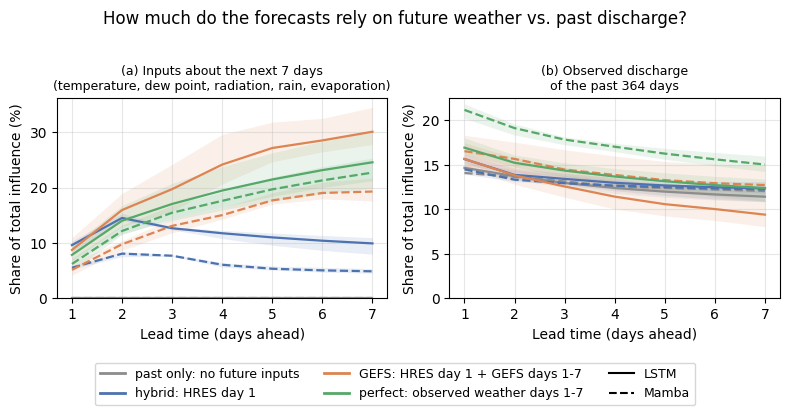

Hình: Mô hình dự báo 7 ngày dựa vào thông tin về thời tiết tương lai bao nhiêu, và thông tin đó thay đổi thế nào khi dự báo xa hơn? Phương pháp Integrated Gradients (IG) chia con số dự báo thành phần đóng góp của từng ô đầu vào (một biến ở một ngày); 'mức ảnh hưởng' là độ lớn phần đóng góp đó, không kể dấu tăng hay giảm. 'Hạn k' là dự báo cho ngày thứ k kể từ ngày phát dự báo. Pha dự báo gồm 5 biến thời tiết của từng ngày trong 7 ngày tới (nhiệt độ 2 m, điểm sương, bức xạ mặt trời, mưa, bốc hơi); cách chỉ quá khứ che hết; cách lai chỉ có dự báo ECMWF HRES của ngày 1; cách GEFS có ECMWF HRES ngày 1 và dự báo GEFS cho ngày 1-7, cùng 5 biến, phát cùng ngày với dự báo; cách hoàn hảo dùng thời tiết thật đã xảy ra (nhiệt độ, điểm sương ERA5-Land, bức xạ E-OBS, mưa MSWEP, bốc hơi GLEAM) - không dùng được khi vận hành, chỉ là cận trên. Mỗi đường là tỉ phần (trong tổng mức ảnh hưởng của mọi đầu vào) của (a) toàn bộ pha dự báo (7 ngày tới) và (b) lưu lượng quan trắc 364 ngày trước; màu là cách c

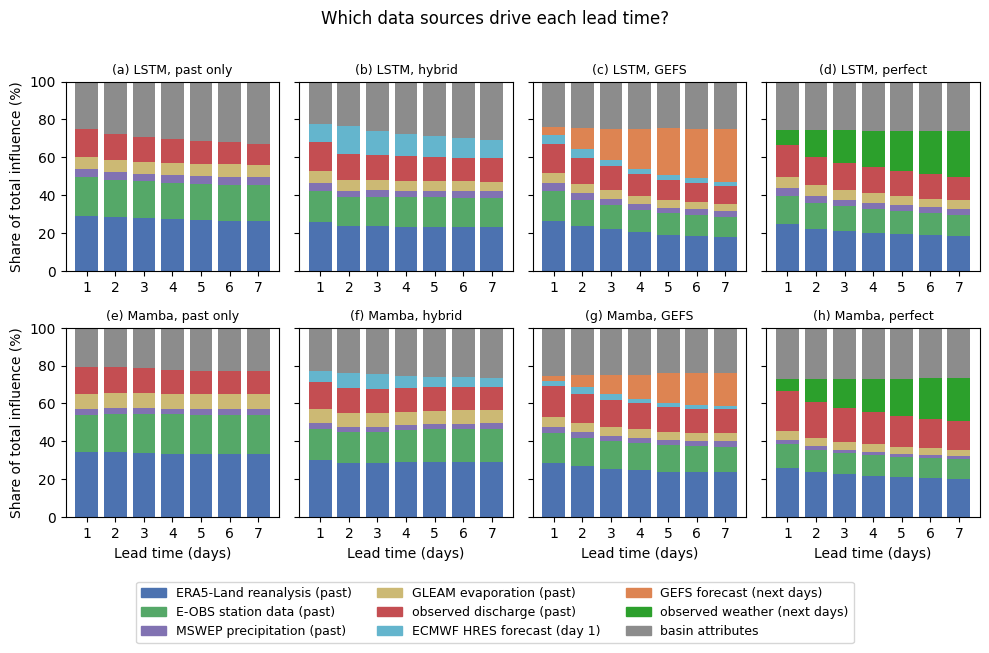

Hình: Ở từng hạn, mô hình lấy thông tin từ nguồn dữ liệu nào? Bảy nguồn đầu là dữ liệu 364 ngày trước ngày phát dự báo (past); ba nguồn sau thuộc 7 ngày tới (dự báo ECMWF HRES, GEFS hoặc thời tiết thật tùy cách). Mỗi cột là một hạn (ngày thứ 1..7 sau ngày phát), chia theo tỉ phần mức ảnh hưởng (tính bằng IG như hình trước) của từng nguồn, cộng lại 100%, trung bình 3 lần huấn luyện. Hàng trên LSTM, hàng dưới Mamba; cột từ trái sang phải là các cách chỉ quá khứ, lai (ECMWF HRES ngày đầu), GEFS (dự báo 7 ngày), hoàn hảo (thời tiết thật của 7 ngày tới). Cách GEFS: phần của dự báo GEFS ở LSTM tăng từ 4% (hạn 1) tới 28% (hạn 7), 2% => 18% ở Mamba; các nguồn quá khứ giảm phần nhiều nhất ở LSTM (hạn 1 => 7): tái phân tích ERA5-Land 8,7%, lưu lượng quan trắc quá khứ 6,3%, lưới trạm E-OBS 4,8%. Thuộc tính lưu vực (diện tích, độ cao, khí hậu trung bình...) chiếm khoảng 21%-33% ở mọi ô. Nguồn lớn nhất ở hạn 7: LSTM chỉ quá khứ - thuộc tính lưu vực; Mamba chỉ quá khứ - tái phân tích ERA5-Land; LSTM

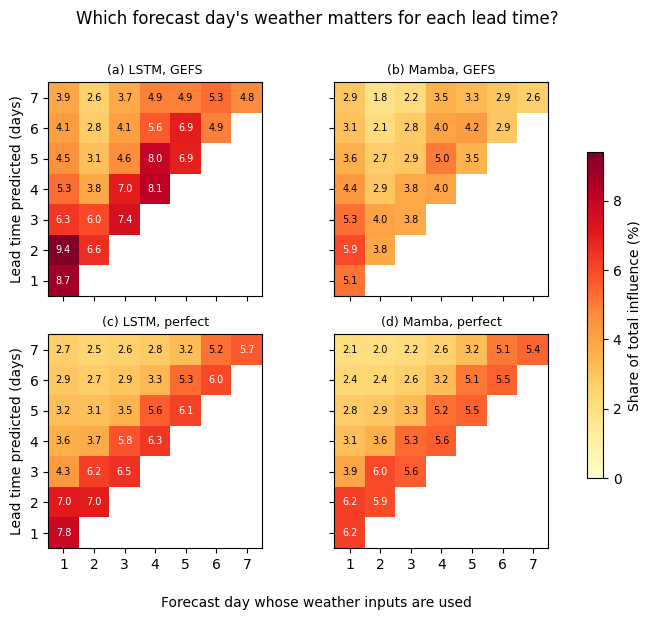

Hình: Khi dự báo cho ngày thứ k, mô hình dùng thời tiết của ngày nào trong các ngày tới? Ô ở hàng k, cột d là tỉ phần mức ảnh hưởng của 5 biến thời tiết (nhiệt độ, điểm sương, bức xạ, mưa, bốc hơi) của ngày d khi dự báo ngày k (số trong ô, %; trung bình 3 lần huấn luyện). Ô phía trên đường chéo để trống: thời tiết của ngày sau ngày cần dự báo không ảnh hưởng (mô hình xử lý chuỗi theo thứ tự thời gian). Hàng trên cách GEFS (ngày 1 gồm cả ECMWF HRES và GEFS, ngày 2-7 chỉ GEFS), hàng dưới cách hoàn hảo (thời tiết thật đã xảy ra); cách lai chỉ có ngày 1 nên không vẽ. Ở hạn 7, thời tiết của chính ngày 7 chiếm 5,7% với LSTM cách hoàn hảo, so với 2,7% của ngày 1 (tỉ số 2,1 lần); với GEFS tỉ số này là 1,2 lần (ngày 7 4,8%, ngày 1 3,9%; ngày 1 gồm cả ECMWF HRES và GEFS hạn 1). Mamba: hoàn hảo 2,6 lần, GEFS 0,9 lần.


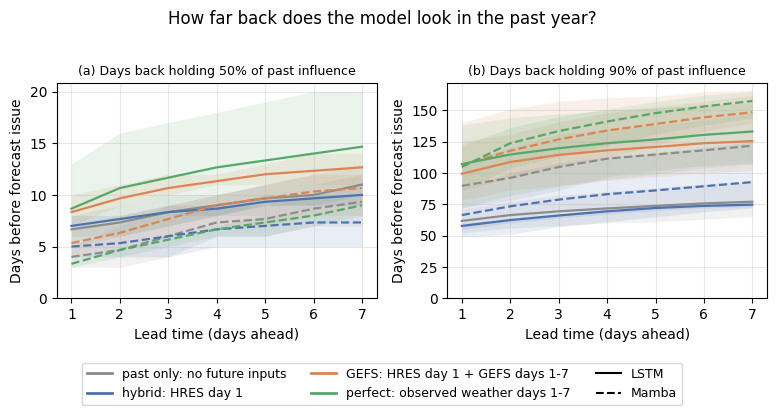

Hình: Mô hình nhìn lại bao xa vào quá khứ, và có nhìn xa hơn khi dự báo xa hơn không? Trong 364 ngày trước ngày phát dự báo, cộng dồn mức ảnh hưởng từ ngày gần nhất lùi dần về trước; 'độ dài nhớ 50%' (a) và '90%' (b) là số ngày phải lùi lại để gom được 50% và 90% ảnh hưởng của phần quá khứ (trung vị qua mẫu). Nửa ảnh hưởng nằm trong khoảng 3-15 ngày gần nhất ở mọi cách; độ dài nhớ 90% ở hạn 7 dài hơn hạn 1 ở 8/8 tổ hợp cách x lõi (LSTM cách GEFS 99 => 125 ngày, Mamba 106 => 148 ngày). Ở cách chỉ quá khứ, hạn 7, độ dài nhớ 90% của Mamba 122 ngày, LSTM 77 ngày; độ lệch chuẩn 3 lần huấn luyện 23 và 14 ngày.


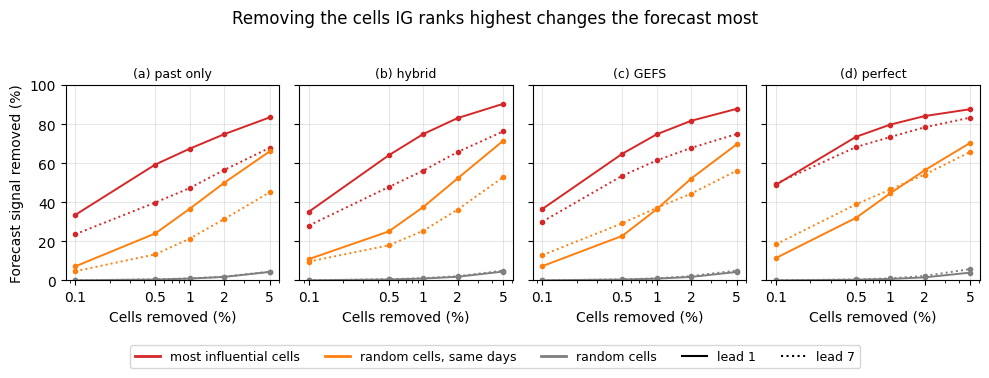

Hình: IG có chỉ đúng những ô mô hình thật sự dựa vào không? Phép kiểm: thay một phần nhỏ ô đầu vào (trục ngang, % số ô của 364 ngày quá khứ và 7 ngày tới) bằng giá trị trung bình rồi đo dự báo đổi bao nhiêu, tính bằng phần chênh lệch giữa dự báo và dự báo của 'ngày trung bình' bị mất đi (trục dọc, trung vị qua 1.000 mẫu, trung bình LSTM, Mamba và 3 lần huấn luyện; nét liền hạn 1, nét chấm hạn 7). Ba cách chọn ô: ô có mức ảnh hưởng IG lớn nhất (đỏ), ô ngẫu nhiên nhưng cùng ngày với ô IG chọn (cam), ô ngẫu nhiên (xám). Xóa 0,1% ô theo IG lấy đi 18%-63% tín hiệu, cùng ngày nhưng chọn biến ngẫu nhiên chỉ 3%-24%, ngẫu nhiên hoàn toàn 0,2%; IG thắng cả hai đối chứng ở 360/360 trường hợp (lần huấn luyện x hạn x tỉ lệ xóa) => IG chọn đúng cả ngày lẫn biến.


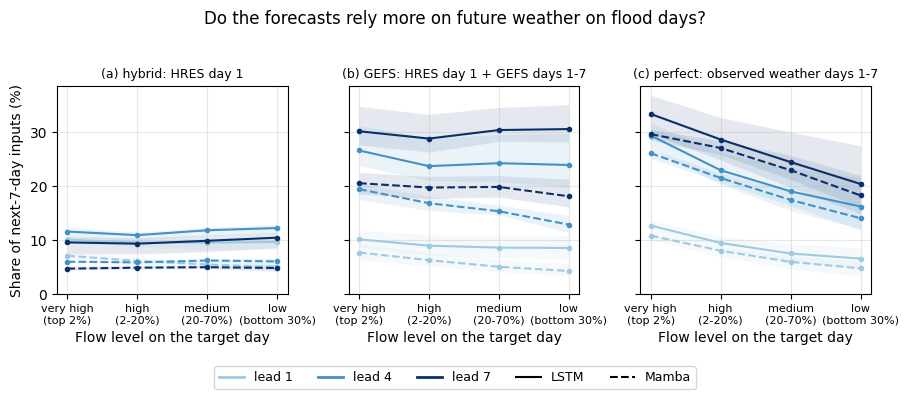

Hình: Vào ngày lũ, mô hình có dựa vào thông tin thời tiết 7 ngày tới nhiều hơn ngày thường không? Trục ngang là mức lưu lượng thật của ngày cần dự báo (ngưỡng riêng từng lưu vực theo số liệu 1981-2013: 'rất cao' là 2% số ngày lớn nhất, 'thấp' là 30% số ngày nhỏ nhất); trục dọc là tỉ phần mức ảnh hưởng của pha dự báo (như hình GH_Future_Share (a)); màu đậm dần theo hạn 1, 4, 7, nét liền LSTM, nét đứt Mamba, dải là khoảng 3 lần huấn luyện. Ở hạn 7, mức rất cao so với mức thấp: lai LSTM 10% so với 10%; lai Mamba 5% so với 5%; GEFS LSTM 30% so với 31%; GEFS Mamba 21% so với 18%; hoàn hảo LSTM 33% so với 20%; hoàn hảo Mamba 30% so với 18%. Chênh lệch lớn nhất ở cách hoàn hảo LSTM (+13,0 điểm %), nhỏ nhất ở cách lai LSTM (-0,9 điểm %).
=> Xong. Hình ở /kaggle/working/g_output/Figures. Chạy Phần 8.


core,mode,seed,notebook
lstm,past,333,14_H_Train_lstm_L2_x1_lr1e-3_past_Seed333
mamba,past,333,14_H_Train_mamba_L2_x1_lr1e-3_past_Seed333
lstm,hybrid,333,14_H_Train_lstm_L2_x1_lr1e-3_hybrid_Seed333
mamba,hybrid,222,14_H_Train_mamba_L2_x1_lr1e-3_hybrid_Seed222
lstm,gefs,222,14_H_Train_lstm_L2_x1_lr1e-3_gefs_Seed222
mamba,gefs,111,14_H_Train_mamba_L2_x1_lr1e-3_gefs_Seed111
lstm,perfect,222,14_H_Train_lstm_L2_x1_lr1e-3_perfect_Seed222
mamba,perfect,333,14_H_Train_mamba_L2_x1_lr1e-3_perfect_Seed333


file,bytes,sha256
Figures/GH_Deletion.png,166335,16fe78d088c0
Figures/GH_Flood_Level.png,179578,dcce7740b704
Figures/GH_Forecast_Days.png,170723,d4a48c2b540a
Figures/GH_Future_Share.png,196756,019eb05f215d
Figures/GH_Group_Share.png,153708,8642066ff720
Figures/GH_Memory_Length.png,178121,5f722ca82a44
Tables/GH_core_diffs.csv,10535,730ce778c324
Tables/GH_deletion.csv,63273,c3200bb2f285
Tables/GH_demo_runs.csv,500,3345055d2b5e
Tables/GH_drop_sensitivity.csv,39949,b80347ced871


mục,giá trị,cần,đạt
24 tệp attribution ig/,24,24,ĐẠT
"Đủ 11 bảng, 6 hình",đủ,đủ,ĐẠT
"Run demo: đúng 1 mỗi (lõi, cách)",8,8,ĐẠT
Mảng demo đúng kích thước,"(24, 451, 7, 9)","(24, 451, 7, 9)",ĐẠT
"Ô (lưu vực, hạn) có mẫu: 3 pha và 9 nhóm cộng lại = 1; 7 ngày = pha dự báo","3157 ô, lệch 1.2e-07",<= 1e-4,ĐẠT
Mảng demo hữu hạn ở ô có mẫu,True,True,ĐẠT
Tổng mẫu theo lưu vực = mẫu giữ theo hạn,36905,36905,ĐẠT
Manifest output khớp,44 / 44,tất cả,ĐẠT
Đã xóa thư mục dữ liệu dựng lại,True,True,ĐẠT


Thời gian Phần 8: 11 giây; cả notebook 4.45 giờ
=> Hoàn thành 02_G_H_XAI. Tải .ipynb, Figures/, Tables/, gh_summary.json về repo; ig/ và demo/ giữ ở Output Kaggle cho demo.


In [1]:
# %% Phần 1 - Cài fork (freeze-H2), mamba-ssm, Captum; kiểm môi trường
# Cài fork theo mã commit (Pipeline Mục 9.1), wheel mamba-ssm theo cell Phần 9 của 01_0_MambaSSM_Build (kiểm Python,
# torch, CUDA khớp lúc dựng => phải giữ môi trường cu128), Captum 0.9.0 --no-deps (phụ thuộc matplotlib, numpy,
# packaging, torch>=2.3, tqdm - đều có sẵn; không để pip đổi torch). In bảng thư viện, môi trường, điều kiện; chưa đạt
# => raise để Save & Run All dừng ngay.
import hashlib
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

SESSION_T0 = time.time()
NOTEBOOK = "02_G_H_XAI"
STEP = "G"
NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "840450f85958538903b16f281ca432d40e0a88e1"   # tag freeze-H2
CAPTUM_VERSION = "0.9.0"                                 # PyPI 17/4/2026, Python >= 3.10, torch >= 2.3
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "scikit-learn", "matplotlib", "packaging", "tqdm",
              "ruamel.yaml"]
NH_MODULES = ["neuralhydrology.modelzoo.sequential_forecast", "neuralhydrology.modelzoo.sf_cores",
              "neuralhydrology.modelzoo.inputlayer", "neuralhydrology.datasetzoo.lamah",
              "neuralhydrology.datautils.gpu_loader", "neuralhydrology.datautils.utils"]
TORCH_RUNS = "2.11.0+cu128"              # torch của mọi run H (ảnh Kaggle 10/2026)

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("g_work")
OUT_DIR = WORK_DIR / "g_output"
WHEEL_ROOTS = [Path("/kaggle/input"), WORK_DIR / "wheels"]
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df, digits=4):
    # Bảng HTML: số thực làm tròn `digits` chữ số, ô trống hiện "-".
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=digits, na_rep="-"))


def show_checks(checks, title="Điều kiện"):
    # checks: [(mục, giá trị, cần, đạt)]; trả True nếu mọi dòng đạt.
    show(title, pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                              for a, b, c, d in checks]))
    return all(c[3] for c in checks)


def run(cmd):
    subprocess.run(cmd, check=True)


def installed_commit(dist):
    # Commit pip ghi lúc cài từ git (direct_url.json của bản cài).
    text = md.distribution(dist).read_text("direct_url.json")
    return json.loads(text)["vcs_info"]["commit_id"] if text else None


def mamba_install():
    # Chép từ 01_0_MambaSSM_Build Phần 9: tìm build_info.json, kiểm Python/torch/CUDA khớp lúc dựng, sha256, cài --no-deps,
    # chạy thử một khối Mamba xuôi + ngược.
    import torch
    infos = [p for root in WHEEL_ROOTS if root.exists() for p in root.rglob("build_info.json")]
    if not infos:
        raise FileNotFoundError("Không thấy build_info.json: gắn Output của notebook 01_0_MambaSSM_Build làm Input")
    if len(infos) > 1:
        print("Thấy nhiều build_info.json, dùng tệp đầu tiên:", *infos, sep="\n  ")
    info_path = infos[0]
    info = json.loads(info_path.read_text())
    now = {"python": platform.python_version(), "torch": torch.__version__, "torch_cuda": torch.version.cuda}
    diff = {k: (info[k], v) for k, v in now.items() if info[k] != v}
    if diff:
        raise RuntimeError(f"Môi trường khác lúc dựng wheel (lúc dựng, bây giờ): {diff}. Copy & Edit một notebook H "
                           "đã chạy để giữ môi trường cu128")
    gpu_cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else None
    if gpu_cc != (7, 5):
        raise RuntimeError(f"Wheel chỉ có mã cho {info['arch']} (T4), GPU hiện tại: {gpu_cc}")
    wheels = []
    for name, digest in info["wheels"].items():
        whl = info_path.parent / name
        if hashlib.sha256(whl.read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"sha256 của {name} không khớp build_info.json")
        wheels.append(str(whl))
    torch_dist = md.version("torch")
    run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", *wheels])
    if md.version("torch") != torch_dist:
        raise RuntimeError("torch bị đổi sau khi cài wheel, khởi động lại phiên và kiểm lại lệnh cài")
    from mamba_ssm import Mamba
    m = Mamba(d_model=16).cuda()
    y = m(torch.randn(2, 8, 16, device="cuda", requires_grad=True))
    y.sum().backward()
    if not torch.isfinite(y).all():
        raise RuntimeError("Khối Mamba chạy thử ra NaN/inf")
    print(f"mamba-ssm đã cài từ {info_path.parent} (dựng {info['built_at']}, torch {info['torch']}, {info['arch']}); "
          f"chạy thử xuôi + ngược đạt")
    return info, info_path


# Cài fork và Captum (không editable, như các notebook trước); ghi thư viện trước/sau để biết pip có đổi gì không
before = installed_versions(CHECK_LIBS)
run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"])
run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", f"captum=={CAPTUM_VERSION}"])
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
NH_INSTALLED_COMMIT = installed_commit("neuralhydrology")
MAMBA_BUILD_INFO, MAMBA_INFO_PATH = mamba_install()
extra = installed_versions(["neuralhydrology", "mamba_ssm", "causal_conv1d", "captum"])

show("Thư viện (sau khi cài fork, mamba-ssm, Captum)", pd.DataFrame({
    "Thư viện": list(extra) + CHECK_LIBS,
    "Phiên bản": [f"{extra['neuralhydrology']} (commit {(NH_INSTALLED_COMMIT or 'không rõ')[:7]})"]
                 + [extra[k] or "THIẾU" for k in list(extra)[1:]] + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] * len(extra) + [f"từ {before[k]}" if before[k] != after[k] else "" for k in CHECK_LIBS]}))

import torch

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có",
    "Wheel mamba-ssm": str(MAMBA_INFO_PATH.parent),
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Nạp thử các module sẽ dùng; sf_cores phải thấy mamba_ssm thì lõi mamba mới dựng được
import_ok = {}
for mod in NH_MODULES + ["captum.attr", "sklearn.linear_model"]:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")

from neuralhydrology.modelzoo import sf_cores

nh_path = Path(importlib.import_module("neuralhydrology").__file__).resolve()
ok = show_checks([
    ("Cài đúng commit freeze-H2", (NH_INSTALLED_COMMIT or "?")[:7], NH_COMMIT[:7], NH_INSTALLED_COMMIT == NH_COMMIT),
    ("Nạp neuralhydrology từ site-packages", nh_path.parent, "site-packages",
     "site-packages" in str(nh_path) or "dist-packages" in str(nh_path)),
    ("Captum", extra["captum"], CAPTUM_VERSION, extra["captum"] == CAPTUM_VERSION),
    ("torch giữ bản của các run H", torch.__version__, TORCH_RUNS, torch.__version__ == TORCH_RUNS),
    ("pip không đổi thư viện có sẵn", ", ".join(f"{k} {before[k]} => {after[k]}" for k in changed) or "không đổi",
     "không đổi", not changed),
    ("Có GPU T4 (dùng GPU 0)", gpus[0] if gpus else "không có", "T4", n_gpu >= 1 and "T4" in gpus[0]),
    ("Nạp được các module", f"{sum(v == 'ĐẠT' for v in import_ok.values())} / {len(import_ok)}", "tất cả",
     all(v == "ĐẠT" for v in import_ok.values())),
    ("sf_cores thấy mamba_ssm", sf_cores.MambaSSM is not None, True, sf_cores.MambaSSM is not None),
])
if not ok:
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print(f"=> Đạt ({time.time() - SESSION_T0:.0f} giây). Chạy Phần 2.")




# %% Phần 2.1 - Tìm Output 24 run H, H Compare, A3; kiểm sha256 theo bàn giao; dựng thư mục dữ liệu qmean_mmd, qmax_mmd
# Notebook huấn luyện H (khuôn Tools/H_Notebook_Template.py, Tools/H_GEFS_Notebook_Template.py Phần 8) ghi
# h_output/environment.json (run_dir tính từ /kaggle/working của notebook đó), summary.json, manifest.csv (cột "tệp");
# 15_H_LamaHCEExt_Compare ghi h_compare/Tables/H_handoff.csv (sha256 best_model.pt, config.yml, train_data_scaler.yml,
# 7 NPZ), h_summary.json (complete, contracts), environment.json (sha256 hai tệp A3), manifest.csv (cột "file"). Nhận run
# theo environment.json, không theo tên thư mục Input. Thư mục dữ liệu: như 01_G_C2_XAI Phần 2 (chép Phần 3.1 khuôn H),
# cùng đường dẫn /kaggle/working/LamaH_q_mmd_input như lúc huấn luyện; kiểm trên khoảng ngày của config H.
import random
import re

import numpy as np
import yaml

from neuralhydrology.datasetzoo.lamah import (_VALID_TARGETS, _normalize_discharge, load_lamah_attributes,
                                              load_lamah_discharge, load_lamah_forcing)

INPUT_ROOT = Path(os.environ.get("G_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "g_input"))
COMMITS = {"freeze-H": "6f68f471bec255f67d446acd6c6556358ff9bfea",
           "freeze-H2": "840450f85958538903b16f281ca432d40e0a88e1"}
MODES = ["past", "hybrid", "gefs", "perfect"]                  # ít => nhiều thông tin tương lai
MODE_TAG = {"past": "freeze-H", "hybrid": "freeze-H", "perfect": "freeze-H", "gefs": "freeze-H2"}
MODE_INPUT = {"past": "none", "hybrid": "first_day", "perfect": "all", "gefs": "gefs"}   # forecast_input_mode
CORES = ["lstm", "mamba"]
CONF = {c: f"{c}_L2_x1_lr1e-3" for c in CORES}                   # 02_Pipeline.md Mục 4.4
SEEDS = [111, 222, 333]
HORIZON = 7
SEQ_LENGTH = 371
N_BASINS = 451
H_COMPARE_VERSION, A3_VERSION = 1, 1
RUN_RE = re.compile(r"^H_(lstm|mamba)_L2_x1_lr1e-3_(past|hybrid|gefs|perfect)_seed(\d+)$")
KEYS = [(c, m, s) for m in MODES for c in CORES for s in SEEDS]
Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
Q_NEW = list(Q_SRC)
LABEL_TOL = 1e-12
N_CHECK = 3
random.seed(0)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def inside(root, relative):
    # Đường dẫn trong manifest/environment phải nằm trong thư mục nguồn.
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f"Đường dẫn nằm ngoài nguồn Input: {relative}")
    return path


def check_manifest(root, manifest_path, required=()):
    # Mọi tệp trong manifest khớp sha256; mọi tệp `required` có trong manifest. Trả (số tệp, danh sách lệch).
    man = pd.read_csv(manifest_path)
    col = "file" if "file" in man else "tệp"
    if col not in man or "sha256" not in man or man[col].duplicated().any():
        raise ValueError(f"Manifest sai cột hoặc trùng đường dẫn: {manifest_path}")
    known = set(man[col])
    rel = [Path(p).resolve().relative_to(Path(root).resolve()).as_posix() for p in required]
    bad = [p for p in rel if p not in known]
    bad += [r for r, dg in zip(man[col], man["sha256"]) if not inside(root, r).is_file() or sha256(inside(root, r)) != dg]
    return len(man), bad


def unique_file(name):
    hits = sorted(INPUT_ROOT.rglob(name))
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng một {name} trong Input, thấy {len(hits)}: {hits}")
    return hits[0]


def find_dir(root, name):
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def find_key(obj, key):
    # Tìm khóa `key` ở mọi tầng của dict lồng nhau (environment.json).
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            hit = find_key(v, key)
            if hit is not None:
                return hit
    return None


def label(key):
    core, mode, seed = key
    return f"{core} {mode} seed{seed}"


# (1) H Compare: manifest, bàn giao 24 run, NPZ 7 hạn, A3 đã dùng
HC_SUMMARY_PATH = unique_file("h_summary.json")
HC_DIR = HC_SUMMARY_PATH.parent
HC_SUMMARY = json.loads(HC_SUMMARY_PATH.read_text(encoding="utf-8"))
HANDOFF = pd.read_csv(HC_DIR / "Tables" / "H_handoff.csv")
hc_files, hc_bad = check_manifest(HC_DIR, HC_DIR / "manifest.csv",
                                  [HC_SUMMARY_PATH, HC_DIR / "Tables" / "H_handoff.csv", HC_DIR / "environment.json"])
HC_ENV = json.loads((HC_DIR / "environment.json").read_text(encoding="utf-8"))
a3_used = find_key(HC_ENV, "A3") or {}
A3_PATHS = {n: unique_file(n) for n in ["A3_persistence_predictions.npz", "A3_Q_source_window.npz"]}
a3_bad = [n for n, p in A3_PATHS.items() if a3_used.get("files", {}).get(n) != sha256(p)]


def npz_path(core, mode, seed, lead):
    # NPZ test/S0 hạn `lead` của run (khóa trong h_summary.json["contracts"], 15_H_LamaHCEExt_Compare Phần 8).
    rel = HC_SUMMARY["contracts"].get(f"SF_{CONF[core]}_H{mode}_seed{seed}_lead{lead}")
    return HC_DIR / rel if rel else None


# (2) Output 24 notebook H: nhận theo environment.json, kiểm với bàn giao
found, dup = {}, []
for env_path in sorted(INPUT_ROOT.rglob("h_output/environment.json")):
    env = json.loads(env_path.read_text(encoding="utf-8"))
    m = RUN_RE.match(env.get("experiment_name", ""))
    if not m:
        continue
    key = (m.group(1), m.group(2), int(m.group(3)))
    if key in found:
        dup.append(label(key))
    root = env_path.parent.parent                # thư mục ứng với /kaggle/working của notebook đó
    found[key] = {"root": root, "out": env_path.parent, "run": inside(root, env["run_dir"]), "env": env}

rows, RUNS = [], {}
for _, h in HANDOFF.iterrows():
    key = (h["lõi"], h["cách"], int(h["hạt giống"]))
    row = {"lõi": key[0], "cách": key[1], "hạt giống": key[2], "notebook": h["notebook"], "epoch chọn": int(h["epoch chọn"])}
    if key not in found:
        rows.append({**row, "lỗi": "THIẾU Input"})
        continue
    r = found[key]
    run_dir, env = r["run"], r["env"]
    summary = json.loads((r["out"] / "summary.json").read_text(encoding="utf-8"))
    cfg = yaml.safe_load((run_dir / "config.yml").read_text(encoding="utf-8-sig"))
    n_files, bad = check_manifest(r["root"], r["out"] / "manifest.csv",
                                  [run_dir / "config.yml", run_dir / "best_model.pt",
                                   run_dir / "train_data" / "train_data_scaler.yml"])
    core, mode, seed = key
    npzs = [npz_path(core, mode, seed, k) for k in range(1, HORIZON + 1)]
    errs = [msg for ok_, msg in [
        (env.get("notebook") == h["notebook"], "tên notebook"),
        (run_dir.name == Path(h["thư mục run"]).name, "thư mục run"),
        (env.get("neuralhydrology_commit") == COMMITS[MODE_TAG[mode]] == h["library_commit"], "commit"),
        (summary.get("status") == "xong" and summary.get("saved_epoch") == int(h["epoch chọn"]), "trạng thái/epoch chọn"),
        (summary.get("n_params") == int(h["số tham số"]), "số tham số"),
        (sha256(run_dir / "best_model.pt") == h["sha256 best_model.pt"], "sha256 best_model.pt"),
        (sha256(run_dir / "config.yml") == h["sha256 config.yml"], "sha256 config.yml"),
        (sha256(run_dir / "train_data" / "train_data_scaler.yml") == h["sha256 train_data_scaler.yml"], "sha256 scaler"),
        (not bad, "manifest"),
        (cfg.get("model") == "sequential_forecast" and cfg.get("sf_core") == core and int(cfg.get("sf_layers")) == 2
         and int(cfg.get("seed")) == seed and int(cfg.get("seq_length")) == SEQ_LENGTH
         and int(cfg.get("forecast_seq_length")) == HORIZON and int(cfg.get("predict_last_n")) == HORIZON
         and cfg.get("forecast_input_mode") == MODE_INPUT[mode] == h["forecast_input_mode"]
         and cfg.get("timestep_counter") is True and cfg.get("target_variables") == ["qmax"], "config"),
        (Path(cfg.get("data_dir", "")) == Q_DIR, "data_dir của config khác thư mục dựng lại"),
        (all(p is not None and p.is_file() for p in npzs), "NPZ H 7 hạn"),
    ] if not ok_]
    RUNS[key] = {**r, "cfg": cfg, "summary": summary, "npz": npzs, "n_params": summary.get("n_params")}
    rows.append({**row, "thư mục run": run_dir.name, "commit": env.get("neuralhydrology_commit", "?")[:7],
                 "số tham số": summary.get("n_params"), "tệp manifest": n_files, "lỗi": "; ".join(errs) or "-"})
RUN_TABLE = pd.DataFrame(rows)
show(f"Output {len(RUNS)} / {len(KEYS)} run H", RUN_TABLE)
extra_runs = sorted(label(k) for k in set(found) - set(RUNS))

# (3) Dữ liệu: danh sách lưu vực, thư mục Q mm/ngày (như 01_G_C2_XAI Phần 2)
LAMAH_DIR = find_dir(INPUT_ROOT, "LamaH_extended")
EXP_DIR = find_dir(INPUT_ROOT, "Experiments")
basins = (EXP_DIR / "basins_filtered.txt").read_text().split()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_raw(data_dir, basin, src):
    # Q (m³/s) của D_gauges, -999 => NaN, đúng hàm bộ nạp gọi cho nhãn.
    return load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]


def q_mmd(data_dir, basin, src):
    # Q (m³/s) => mm/ngày theo area_gov, đúng phép tính bộ nạp dùng cho nhãn.
    return _normalize_discharge(ser=q_raw(data_dir, basin, src), area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


def rel_diff(a, b):
    # Lệch tương đối lớn nhất trên các ô cả hai có số, và số ô khác trạng thái trống.
    both = ~np.isnan(a) & ~np.isnan(b)
    rel = np.abs(a[both] - b[both]) / np.maximum(np.abs(b[both]), 1e-300)
    return (float(rel.max()) if rel.size else 0.0), int((np.isnan(a) != np.isnan(b)).sum())


t0 = time.time()
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
n_ok = sum(has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv") for b in basins)

keep_rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    keep_rows.append(new.drop(columns=Q_NEW).equals(src))
if not RUNS:
    raise RuntimeError("Chưa nhận được run H nào - kiểm Input (bảng ở trên)")
CFG0 = next(iter(RUNS.values()))["cfg"]
WIN_START = pd.to_datetime(CFG0["train_start_date"], dayfirst=True) - pd.Timedelta(days=SEQ_LENGTH - 1)
WIN_END = pd.to_datetime(CFG0["test_end_date"], dayfirst=True)
TRAIN_END = pd.to_datetime(CFG0["train_end_date"], dayfirst=True)
max_label = max_mean = 0.0
n_nan = 0
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a").loc[WIN_START:WIN_END]
    for col, src in Q_SRC.items():
        r_, n_ = rel_diff(df[col].to_numpy(), q_mmd(Q_DIR, b, src).reindex(df.index).to_numpy())
        n_nan += n_
        if col == "qmax_mmd":
            max_label = max(max_label, r_)
        else:
            max_mean = max(max_mean, r_)

periods = {(c["cfg"]["train_start_date"], c["cfg"]["train_end_date"], c["cfg"]["test_start_date"],
            c["cfg"]["test_end_date"]) for c in RUNS.values()}
ok = show_checks([
    ("H Compare: manifest, complete", f"{hc_files - len(hc_bad)} / {hc_files} tệp khớp, complete="
     f"{HC_SUMMARY.get('complete')}", "tất cả, True", not hc_bad and HC_SUMMARY.get("complete") is True),
    ("Bàn giao có 24 run", len(HANDOFF), 24, len(HANDOFF) == 24 and {tuple(x) for x in HANDOFF[["lõi", "cách"]].values}
     == {(c, m) for c in CORES for m in MODES}),
    ("A3: sha256 trùng bản H Compare đã dùng", ", ".join(a3_bad) or "trùng", "trùng", not a3_bad),
    ("Run H có đủ và không lỗi", f"{int(RUN_TABLE['lỗi'].eq('-').sum())} / 24", 24,
     len(RUNS) == 24 and bool(RUN_TABLE["lỗi"].eq("-").all())),
    ("Không gắn trùng hoặc thừa Output H", (dup + extra_runs) or "không", "không", not dup and not extra_runs),
    ("24 config cùng kỳ dữ liệu", len(periods), 1, len(periods) == 1),
    ("Danh sách lưu vực", f"{len(basins)} ({len(set(basins))} mã khác nhau)", N_BASINS,
     len(basins) == len(set(basins)) == N_BASINS),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)})", len(basins),
     n_ok == len(basins)),
    (f"{N_CHECK} lưu vực ngẫu nhiên giữ nguyên cột cũ", f"{sum(keep_rows)} / {N_CHECK}", N_CHECK, all(keep_rows)),
    (f"qmax_mmd = nhãn qmax, qmean_mmd = qmean D_gauges ({WIN_START.date()} - {WIN_END.date()})",
     f"lệch {max_label:.2g} / {max_mean:.2g}; ô trống khác {n_nan}", f"<= {LABEL_TOL}; 0",
     max(max_label, max_mean) <= LABEL_TOL and n_nan == 0),
], "Điều kiện Phần 2.1")
print(f"Thời gian Phần 2.1: {time.time() - t0:.0f} giây")
if not ok:
    raise RuntimeError("Phần 2.1 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 2.2.")


# %% Phần 2.2 - Thêm 35 cột GEFS theo hạn vào tệp khí tượng của thư mục dữ liệu
# Chép Phần 3.2 của khuôn Tools/H_GEFS_Notebook_Template.py (đã chạy đạt ở 6 run gefs): nguồn Output 04_GEFS_Download
# Version 6, gefs/gefs_lamah_daily.npz (values [451 lưu vực, 01/01/2003 - 31/12/2017, 35 cột] float32; cột
# GEFS_<biến>_lead<k> tại ngày d = dự báo cho ngày d phát 00 UTC ngày d-k+1). Ghi 9 chữ số có nghĩa (float32 đọc lại
# đúng từng bit), ngày ngoài 2003-2017 và ô trống để trống. Cột GEFS chỉ nằm trong dynamic_inputs của 6 run gefs; ba
# cách còn lại đọc cùng thư mục, bộ nạp chỉ giữ cột trong dynamic_inputs của run (lamah.py dòng 277). Kiểm như khuôn:
# đúng bản (sha256), lưu vực/ngày/tên cột, ô trống đúng chỗ đã biết, đọc lại 451 lưu vực trùng từng bit, cột cũ giữ nguyên.
GEFS_SHA256 = "bcc0c55cc46c17d24de7517147c9b86a971f563703970d37ee0726b23dc681d4"   # 04_GEFS_Download Version 6
GEFS_REL = "gefs/gefs_lamah_daily.npz"
GEFS_VARS = ("t2m", "d2m", "ssrd", "tp", "e")   # thứ tự biến GEFS mỗi hạn, ứng với 5 biến ECMWF HRES
GEFS_COLS = [f"GEFS_{v}_lead{k}" for k in range(1, HORIZON + 1) for v in GEFS_VARS]
GEFS_FIRST, GEFS_LAST = pd.Timestamp("2003-01-01"), pd.Timestamp("2017-12-31")
GEFS_GAP_CELLS = 30                      # ô trống mỗi lưu vực: 6 chỗ đã biết (04_GEFS_Download Phần 1, KNOWN_GAPS)


def has_gefs_cols(path):
    return path.exists() and set(GEFS_COLS) <= set(path.open().readline().strip().split(";"))


def add_gefs(basin, block):
    # Ghép 35 cột (float32 => float64 đúng giá trị) theo ngày vào tệp đã dựng; ghi qua tệp tạm rồi đổi tên.
    path = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    df = read_text_csv(path)
    g = pd.DataFrame(block.astype(np.float64), index=GEFS_DATES, columns=GEFS_COLS).reindex(df["_key"])
    out = pd.concat([df.drop(columns="_key"), g.reset_index(drop=True)], axis=1)
    tmp = path.with_suffix(".tmp")
    out.to_csv(tmp, sep=";", index=False, float_format="%.9g")
    tmp.replace(path)


# (1) Output 04_GEFS_Download
t0 = time.time()
GEFS_SUMMARY_PATH = unique_file("gefs_summary.json")
GEFS_SUMMARY = json.loads(GEFS_SUMMARY_PATH.read_text(encoding="utf-8"))
GEFS_NPZ = GEFS_SUMMARY_PATH.parent / GEFS_REL
listed = {m["tệp"]: m["sha256"] for m in GEFS_SUMMARY.get("manifest", [])}
npz_sha = sha256(GEFS_NPZ) if GEFS_NPZ.exists() else "THIẾU"
with np.load(GEFS_NPZ) as z:
    GEFS_VALUES = z["values"]
    gefs_basins = [str(b) for b in z["basins"]]
    GEFS_DATES = pd.DatetimeIndex(pd.to_datetime(z["dates"]))
    gefs_columns = [str(c) for c in z["columns"]]
gap_mask = np.zeros(GEFS_VALUES.shape[1:], bool)
gaps = GEFS_SUMMARY.get("known_gaps", [])
for gap in gaps:
    for lead in gap["leads"]:
        day = pd.Timestamp(gap["init"]) + pd.Timedelta(days=lead - 1)
        if GEFS_FIRST <= day <= GEFS_LAST:
            gap_mask[GEFS_DATES.get_loc(day), GEFS_COLS.index(f"GEFS_{gap['variable']}_lead{lead}")] = True
nan_cells = np.isnan(GEFS_VALUES)
gap_days = GEFS_DATES[gap_mask.any(axis=1)]
src_checks = [
    ("gefs_summary.json: đủ năm, mọi kiểm Phần 4 đạt", f"complete {GEFS_SUMMARY.get('complete')}", "True",
     GEFS_SUMMARY.get("complete") is True and bool(GEFS_SUMMARY.get("checks")) and all(GEFS_SUMMARY["checks"].values())),
    (f"sha256 {GEFS_REL} = Version 6 = danh mục 04_GEFS_Download", npz_sha[:12], GEFS_SHA256[:12],
     npz_sha == GEFS_SHA256 == listed.get(GEFS_REL)),
    ("Lưu vực đủ 451, trùng basins_filtered.txt", len(gefs_basins), N_BASINS,
     sorted(gefs_basins) == sorted(basins) and len(set(gefs_basins)) == len(basins)),
    ("Ngày 01/01/2003 - 31/12/2017 liền mạch", f"{GEFS_DATES[0].date()} - {GEFS_DATES[-1].date()}", "đủ",
     GEFS_DATES.equals(pd.date_range(GEFS_FIRST, GEFS_LAST))),
    ("35 cột GEFS_(biến)_lead(hạn) đúng thứ tự", len(gefs_columns), len(GEFS_COLS), gefs_columns == GEFS_COLS),
    ("Mảng float32 [lưu vực, ngày, cột]", f"{GEFS_VALUES.dtype} {GEFS_VALUES.shape}", "float32",
     GEFS_VALUES.dtype == np.float32 and GEFS_VALUES.shape == (len(basins), len(GEFS_DATES), len(GEFS_COLS))),
    ("Tên cột GEFS ngoài _VALID_TARGETS", [c for c in GEFS_COLS if c.lower() in _VALID_TARGETS] or "ngoài", "ngoài",
     not [c for c in GEFS_COLS if c.lower() in _VALID_TARGETS]),
    (f"Ô trống = {len(gaps)} chỗ đã biết ({GEFS_GAP_CELLS} ô mỗi lưu vực), nằm trong kỳ train",
     f"{int(nan_cells.sum()):,} ô, mỗi lưu vực {int(gap_mask.sum())}", GEFS_GAP_CELLS,
     bool((nan_cells == gap_mask[None]).all()) and int(gap_mask.sum()) == GEFS_GAP_CELLS
     and len(gap_days) > 0 and gap_days.max() <= TRAIN_END),
]
if not show_checks(src_checks, f"Output 04_GEFS_Download ({GEFS_SUMMARY_PATH.parent})"):
    raise RuntimeError("Phần 2.2 CHƯA đạt: Output 04_GEFS_Download không đúng bản hoặc nội dung lệch - dừng notebook")

# (2) Thêm cột vào 451 tệp, đọc lại bằng đường của bộ nạp
gefs_pos = {b: i for i, b in enumerate(gefs_basins)}
todo = [b for b in basins if not has_gefs_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    add_gefs(b, GEFS_VALUES[gefs_pos[b]])
read_bad = {"lệch npz": [], "có giá trị ngoài 2003-2017": [], "thiếu cột Q": [], "thiếu ngày": []}
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    if not set(Q_NEW) <= set(df.columns):
        read_bad["thiếu cột Q"].append(b)
    if GEFS_DATES.difference(df.index).size:
        read_bad["thiếu ngày"].append(b)
    if not np.array_equal(df[GEFS_COLS].reindex(GEFS_DATES).to_numpy().astype(np.float32), GEFS_VALUES[gefs_pos[b]],
                          equal_nan=True):
        read_bad["lệch npz"].append(b)
    if df.loc[(df.index < GEFS_FIRST) | (df.index > GEFS_LAST), GEFS_COLS].notna().to_numpy().any():
        read_bad["có giá trị ngoài 2003-2017"].append(b)
keep_rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    q_text = all(new[c].equals(fmt(new["_key"].map(q_mmd(LAMAH_DIR, b, s)))) for c, s in Q_SRC.items())
    keep_rows.append(new.drop(columns=Q_NEW + GEFS_COLS).equals(src) and q_text)
n_gefs_ok = sum(has_gefs_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv") for b in basins)
ok = show_checks([
    ("Tệp có đủ 35 cột GEFS", f"{n_gefs_ok} / {len(basins)} (thêm mới {len(todo)})", len(basins),
     n_gefs_ok == len(basins)),
    *[(f"Lưu vực {k} (đọc bằng load_lamah_forcing)", len(v), 0, not v) for k, v in read_bad.items()],
    (f"{N_CHECK} lưu vực ngẫu nhiên giữ nguyên cột khí tượng và cột Q", f"{sum(keep_rows)} / {N_CHECK}", N_CHECK,
     all(keep_rows)),
], "Điều kiện Phần 2.2")
print(f"Thời gian Phần 2.2: {time.time() - t0:.0f} giây")
if not ok:
    raise RuntimeError("Phần 2.2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")



# %% Phần 3 - Nạp 24 mô hình, dataset test của 4 cách, rút mẫu phân tầng, kiểm dự báo 7 hạn trùng NPZ H
# Dữ liệu: mỗi cách một dataset kỳ test 451 lưu vực (basin=None, scaler của run => không lọc mẫu, như Tester); 6 run
# cùng cách có cùng biến đầu vào và scaler. Dataset tự che pha dự báo theo cách trong __getitem__ (basedataset.py dòng
# 214-215, forecast_inputs.py ở 840450f: past che mọi ngày ECMWF HRES, hybrid giữ ngày đầu, gefs giữ ECMWF HRES ngày đầu
# và ở bước k chỉ nhóm GEFS hạn k, perfect giữ tái phân tích 7 ngày) => ô bị che là NaN đúng như mô hình thấy khi dự báo.
# Mẫu (ngày phát i = ngày dự báo đầu, ngày cuối mẫu = i + 6 = ngày đích hạn 7, như 15_H_LamaHCEExt_Compare Phần 3): mỗi
# lưu vực N_PER_LEVEL ngày phát mỗi mức của qmax quan trắc LỚN NHẤT trong 7 ngày đích (ngưỡng riêng lưu vực trên qmax
# 1981-2013, như 01_G_C2_XAI) => đủ mẫu "tuần tới có lũ"; bảng theo hạn ở Phần 5 tách mức theo ngày đích của từng hạn.
# Chỉ ngày phát có 7 quan trắc và dự báo 7 hạn hữu hạn ở cả 24 run. Rút bằng hoán vị ngẫu nhiên cố định rồi lấy
# N_PER_LEVEL ngày đầu => giảm N_PER_LEVEL cho ra tập con của tập lớn hơn.
# Đầu vào gói thành 3 tensor (pha quá khứ [mẫu, 364, cột], pha dự báo [mẫu, 7, cột của cách], thuộc tính [mẫu, cột]) +
# mặt nạ NaN + bộ đếm hạn (hindcast_counter 0, forecast_counter 1..7, basedataset.py dòng 84-94; InputLayer nối vào
# sau masked mean, inputlayer.py dòng 243-245 => truyền cố định, không giải thích). Kiểm: (1) dự báo eval 7 hạn trùng
# NPZ H hạn k ở ngày đích i + k - 1 (dung sai DemoRuntime); (2) hàm bọc + chế độ đạo hàm trùng eval; (3) đạo hàm hữu
# hạn, ô NaN đạo hàm 0; (4) pha quá khứ giống nhau ở 4 cách (che chỉ đụng pha dự báo).
from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.modelzoo import get_model
from neuralhydrology.utils.config import Config

DEVICE = torch.device("cuda:0")
TABLE_DIR = OUT_DIR / "Tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
LEVELS = ["very high", "high", "medium", "low"]  # xác suất vượt 0-0.02, 0.02-0.2, 0.2-0.7, 0.7-1
LEVEL_EXCEED = [0.02, 0.2, 0.7]
N_PER_LEVEL = 3
SAMPLE_SEED = 2026
REF_YEARS = ("1981-01-01", "2013-12-31")           # qmax trước kỳ test, như A1 và bộ đánh giá
PRED_ATOL, PRED_RTOL = 2e-5, 1e-6                  # Workspace/07_Demo/DemoRuntime/forecast.py
BATCH = 256
LEADS = list(range(1, HORIZON + 1))
N_HIND = SEQ_LENGTH - HORIZON                      # 364 ngày pha quá khứ
SEASONS = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA",
           9: "SON", 10: "SON", 11: "SON"}
COUNTERS = ("hindcast_counter", "forecast_counter")


def group_label(cols):
    # Nhóm nguồn từ tiền tố cột: hai cột Q quan trắc => "Q"; ECMWF HRES => "ECMWF"; nhóm GEFS hạn k => "GEFS_lead<k>";
    # nhóm trộn ERA5L, EOBS, MSWEP, GLEAM của cách hoàn hảo (pha dự báo) => "REANALYSIS".
    if all(c.startswith("q") for c in cols):
        return "Q"
    if all(c.startswith("GEFS_") for c in cols):
        leads = {int(c.rsplit("lead", 1)[1]) for c in cols}
        if len(leads) != 1:
            raise ValueError(f"Nhóm GEFS trộn nhiều hạn: {cols}")
        return f"GEFS_lead{leads.pop()}"
    prefixes = {c.split("_")[0] for c in cols}
    if len(prefixes) == 1:
        return prefixes.pop()
    if prefixes <= {"ERA5L", "EOBS", "MSWEP", "GLEAM"}:
        return "REANALYSIS"
    raise ValueError(f"Nhóm trộn nhiều nguồn: {cols}")


def run_cfg(r):
    # Config của run, đổi đường dẫn danh sách lưu vực sang Input và thiết bị sang GPU 0.
    cfg = Config(r["run"] / "config.yml")
    basin_file = EXP_DIR / "basins_filtered.txt"
    cfg.update_config({"train_basin_file": basin_file, "validation_basin_file": basin_file,
                       "test_basin_file": basin_file, "device": "cuda:0", "data_dir": Q_DIR})
    return cfg


def groups_of(inputs):
    return [list(g) if isinstance(g, (list, tuple)) else g for g in inputs]


def ig_mode(model):
    # Chế độ tính đạo hàm: mọi dropout ở eval; nn.LSTM ở train() để cuDNN có backward (không có dropout trong).
    model.eval()
    rnn = getattr(model.core, "rnn", None)
    if rnn is not None:
        if rnn.dropout != 0:
            raise RuntimeError("RNN có dropout trong - không dùng train() thay eval được")
        rnn.train()
    return model


def forward_packed(model, fore_feats, h, f, s, mh, mf, hc, fc):
    # Hàm bọc: dựng lại dict đầu vào của mô hình (ô có mặt nạ đặt lại NaN, bộ đếm hạn cố định); trả dự báo chuẩn hóa
    # 7 hạn [mẫu, 7].
    nan = torch.tensor(float("nan"), device=h.device, dtype=h.dtype)
    h = torch.where(mh, nan, h)
    f = torch.where(mf, nan, f)
    x_h = {k: h[..., i:i + 1] for i, k in enumerate(HIND_FEATS)}
    x_f = {k: f[..., i:i + 1] for i, k in enumerate(fore_feats)}
    x_h["hindcast_counter"], x_f["forecast_counter"] = hc, fc
    return model({"x_d_hindcast": x_h, "x_d_forecast": x_f, "x_s": s})["y_hat"][:, -HORIZON:, 0]


def chunks(n, size=BATCH):
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]


def to_dev(*xs):
    return [x.to(DEVICE) for x in xs]


def counters(n):
    # Bộ đếm hạn cho n mẫu (giống nhau ở mọi mẫu, kiểm ở (4)).
    return HC0.expand(n, -1, -1).to(DEVICE), FC0.expand(n, -1, -1).to(DEVICE)


def read_npz(key):
    # 7 NPZ của run => sim_raw [hạn, ngày đích, lưu vực] (mm/ngày, chưa chặn âm) và (ngày đích, ID, obs) nếu 7 tệp
    # cùng ngữ cảnh, ngược lại (None, None, None).
    sims, meta = [], None
    for p in RUNS[key]["npz"]:
        with np.load(p, allow_pickle=False) as d:
            sims.append(np.array(d["sim_raw_mm_day"], dtype=float))
            cur = (np.array(d["dates"], dtype="datetime64[D]"), [str(b) for b in d["basin_ids"]],
                   np.array(d["obs_mm_day"], dtype=float))
        if meta is None:
            meta = cur
        elif not (meta[0] is not None and np.array_equal(cur[0], meta[0]) and cur[1] == meta[1]
                  and np.array_equal(cur[2], meta[2], equal_nan=True)):
            meta = (None, None, None)
    return np.stack(sims), meta


t0 = time.time()
# (1) Config, scaler, biến đầu vào theo cách
CFGS = {k: run_cfg(r) for k, r in RUNS.items()}
MODE_REF = {m: next(k for k in KEYS if k[1] == m) for m in MODES}


def cfg_sig(c):
    return repr((c.hindcast_inputs, c.forecast_inputs, c.static_attributes, c.seq_length, c.forecast_seq_length,
                 c.predict_last_n, c.nan_handling_method, c.timestep_counter, c.forecast_input_mode))


same_in_mode = all(cfg_sig(CFGS[k]) == cfg_sig(CFGS[MODE_REF[k[1]]]) for k in KEYS)
same_hind = len({repr((CFGS[k].hindcast_inputs, CFGS[k].static_attributes)) for k in KEYS}) == 1
same_scaler = bool((HANDOFF.groupby("cách")["sha256 train_data_scaler.yml"].nunique() == 1).all())
cfg0 = CFGS[MODE_REF[MODES[0]]]
HIND_FEATS = list(cfg0.hindcast_inputs_flattened)
STATICS = list(cfg0.static_attributes)
HIND_GROUPS = groups_of(cfg0.hindcast_inputs)
FORE_FEATS = {m: list(CFGS[MODE_REF[m]].forecast_inputs_flattened) for m in MODES}
FORE_GROUPS = {m: groups_of(CFGS[MODE_REF[m]].forecast_inputs) for m in MODES}
if not all(isinstance(g, list) for g in HIND_GROUPS + sum(FORE_GROUPS.values(), [])):
    raise RuntimeError("Config không chia nhóm nguồn (masked mean) - khác giao thức H")
HIND_GROUP_OF = {c: group_label(g) for g in HIND_GROUPS for c in g}
FORE_GROUP_OF = {m: {c: group_label(g) for g in FORE_GROUPS[m] for c in g} for m in MODES}
FORE_LABELS = {m: [group_label(g) for g in FORE_GROUPS[m]] for m in MODES}
SCALERS = {m: load_scaler(RUNS[MODE_REF[m]]["run"]) for m in MODES}
Q_SCALE = float(SCALERS[MODES[0]]["xarray_feature_scale"]["qmax"].item())
Q_CENTER = float(SCALERS[MODES[0]]["xarray_feature_center"]["qmax"].item())
same_q_scale = all(float(SCALERS[m]["xarray_feature_scale"]["qmax"].item()) == Q_SCALE
                   and float(SCALERS[m]["xarray_feature_center"]["qmax"].item()) == Q_CENTER for m in MODES)
show("Biến đầu vào theo pha (pha quá khứ và thuộc tính giống nhau ở 4 cách)", pd.DataFrame(
    [{"pha": "quá khứ (364 ngày)", "cách": "cả 4", "nhóm": group_label(g), "số cột": len(g), "cột": ", ".join(g)}
     for g in HIND_GROUPS]
    + [{"pha": "dự báo (7 ngày)", "cách": m, "nhóm": group_label(g), "số cột": len(g), "cột": ", ".join(g)}
       for m in MODES for g in FORE_GROUPS[m]]
    + [{"pha": "tĩnh", "cách": "cả 4", "nhóm": "static", "số cột": len(STATICS),
        "cột": ", ".join(STATICS[:6]) + ", ..."}]))

# (2) Dataset kỳ test mỗi cách; chỉ mục (lưu vực, ngày phát) => mẫu (ngày cuối mẫu = ngày phát + 6)
DATASETS, INDEX = {}, {}
for m in MODES:
    ds = get_dataset(CFGS[MODE_REF[m]], is_train=False, period="test", basin=None, scaler=SCALERS[m])
    DATASETS[m] = ds
    INDEX[m] = {(str(b), pd.Timestamp(ds._dates[b]["1D"][idx[0]]) - pd.Timedelta(days=HORIZON - 1)): i
                for i, (b, idx) in ds.lookup_table.items()}
    print(f"Dataset test {m}: {len(ds):,} mẫu, {len(ds.basins)} lưu vực ({time.time() - t0:.0f} giây)")
same_index = all(INDEX[m] == INDEX[MODES[0]] for m in MODES)

# (3) NPZ H: ngày đích chung, quan trắc; ngày phát hợp lệ ở cả 24 run; rút mẫu phân tầng theo mức lớn nhất 7 ngày
_, (NPZ_DAYS, NPZ_IDS, OBS) = read_npz(KEYS[0])
if NPZ_DAYS is None:
    raise RuntimeError(f"7 NPZ của {label(KEYS[0])} khác ngữ cảnh - kiểm Output 15_H_LamaHCEExt_Compare")
NPZ_DATES = pd.DatetimeIndex(NPZ_DAYS)
n_t = len(NPZ_DATES)
n_o = n_t - (HORIZON - 1)                          # ngày phát có đủ 7 ngày đích trong NPZ
same_ctx = True
fin = np.ones((n_t, len(NPZ_IDS)), bool)           # dự báo mọi hạn của mọi run hữu hạn ở ngày đích
for key in KEYS:
    sim, meta = read_npz(key)
    same_ctx &= bool(meta[0] is not None and np.array_equal(meta[0], NPZ_DAYS) and meta[1] == NPZ_IDS
                     and np.array_equal(meta[2], OBS, equal_nan=True))
    fin &= np.isfinite(sim).all(axis=0)
OBS_WIN = np.stack([OBS[k - 1:k - 1 + n_o] for k in LEADS], axis=1)          # [ngày phát, hạn, lưu vực]
FIN_WIN = np.stack([fin[k - 1:k - 1 + n_o] for k in LEADS], axis=1)
obs_ok = np.isfinite(OBS_WIN).all(axis=1)
valid = obs_ok & FIN_WIN.all(axis=1)                                         # [ngày phát, lưu vực]
OBS_MAX = np.where(obs_ok, np.max(np.where(np.isfinite(OBS_WIN), OBS_WIN, -np.inf), axis=1), np.nan)
rng = np.random.default_rng(SAMPLE_SEED)
sample_rows, level_rows, THRESH = [], [], {}
for j, b in enumerate(NPZ_IDS):
    ref = q_mmd(LAMAH_DIR, b, "qmax").loc[REF_YEARS[0]:REF_YEARS[1]].dropna().to_numpy()
    if ref.size == 0:
        level_rows.append({"lưu vực": b, "số năm tham chiếu": 0})
        continue
    thr = np.quantile(ref, [1 - p for p in LEVEL_EXCEED])           # ngưỡng rất cao > cao > trung bình
    THRESH[b] = thr
    om = OBS_MAX[:, j]
    lvl = np.where(om >= thr[0], 0, np.where(om >= thr[1], 1, np.where(om >= thr[2], 2, 3)))
    for li, name in enumerate(LEVELS):
        days = np.flatnonzero(valid[:, j] & (lvl == li))
        for t in np.sort(rng.permutation(days)[:N_PER_LEVEL]):
            sample_rows.append({"basin": b, "origin": NPZ_DATES[t], "level": name, "o_index": int(t), "b_index": j,
                                "obs_max_mm_day": float(om[t]),
                                **{f"obs_lead{k}": float(OBS_WIN[t, k - 1, j]) for k in LEADS}})
    level_rows.append({"lưu vực": b, "số năm tham chiếu": round(ref.size / 365.25, 1),
                       **{f"ngày phát mức {n}": int((valid[:, j] & (lvl == li)).sum()) for li, n in enumerate(LEVELS)}})
SAMPLES = pd.DataFrame(sample_rows)
SAMPLES["season"] = SAMPLES["origin"].dt.month.map(SEASONS)
for m in MODES:
    SAMPLES[f"ds_{m}"] = [INDEX[m].get((b, d), -1) for b, d in zip(SAMPLES["basin"], SAMPLES["origin"])]
LEVEL_TABLE = pd.DataFrame(level_rows)
show("Số mẫu theo mức (qmax lớn nhất 7 ngày đích) và mùa của ngày phát",
     SAMPLES.pivot_table(index="level", columns="season", values="basin", aggfunc="size", fill_value=0)
     .reindex(LEVELS).reset_index())

# (4) Gói đầu vào (CPU) mỗi cách; pha quá khứ, thuộc tính, bộ đếm giống nhau ở 4 cách
HIN = MASK_H = S_RAW = HC0 = FC0 = None
FIN, MASK_F = {}, {}
extra_keys, hind_same, cnt_ok = set(), True, True
for m in MODES:
    ds = DATASETS[m]
    H_list, F_list, S_list = [], [], []
    for sl in chunks(len(SAMPLES), 1024):
        batch = ds.collate_fn([ds[int(i)] for i in SAMPLES[f"ds_{m}"].iloc[sl]])
        xh, xf = batch["x_d_hindcast"], batch["x_d_forecast"]
        extra_keys |= (set(xh) - set(HIND_FEATS) - {COUNTERS[0]}) | (set(xf) - set(FORE_FEATS[m]) - {COUNTERS[1]})
        hc, fc = xh[COUNTERS[0]], xf[COUNTERS[1]]
        if HC0 is None:
            HC0, FC0 = hc[:1].clone(), fc[:1].clone()
        cnt_ok &= bool((hc == HC0).all() and (fc == FC0).all())
        H_list.append(torch.cat([xh[k] for k in HIND_FEATS], dim=-1))
        F_list.append(torch.cat([xf[k] for k in FORE_FEATS[m]], dim=-1))
        S_list.append(batch["x_s"])
    h_raw, f_raw, s_raw = torch.cat(H_list), torch.cat(F_list), torch.cat(S_list)
    if HIN is None:
        HIN, MASK_H, S_RAW = torch.nan_to_num(h_raw, nan=0.0), torch.isnan(h_raw), s_raw
    else:
        hind_same &= bool(torch.equal(torch.isnan(h_raw), MASK_H) and torch.equal(torch.nan_to_num(h_raw, nan=0.0), HIN)
                          and torch.equal(s_raw, S_RAW))
    FIN[m], MASK_F[m] = torch.nan_to_num(f_raw, nan=0.0), torch.isnan(f_raw)
    del h_raw, f_raw, H_list, F_list
cnt_ok &= (tuple(HC0.shape) == (1, N_HIND, 1) and bool((HC0 == 0).all())
           and torch.equal(FC0.flatten(), torch.arange(1, HORIZON + 1, dtype=FC0.dtype)))
show(f"Gói đầu vào ({time.time() - t0:.0f} giây; tỉ lệ ô trống)", pd.DataFrame(
    [{"cách": m, "quá khứ": str(tuple(HIN.shape)), "dự báo": str(tuple(FIN[m].shape)), "tĩnh": str(tuple(S_RAW.shape)),
      "ô trống quá khứ": f"{MASK_H.float().mean():.2%}",
      **{f"dự báo ngày {k}": f"{MASK_F[m][:, k - 1].float().mean():.0%}" for k in LEADS}} for m in MODES]))

# (5) Nạp 24 mô hình; dự báo eval 7 hạn so NPZ; hàm bọc + chế độ đạo hàm so eval; đạo hàm hữu hạn, ô NaN đạo hàm 0
MODELS, PRED, check_rows = {}, {}, []
o_idx, b_idx = SAMPLES["o_index"].to_numpy(), SAMPLES["b_index"].to_numpy()
for key in KEYS:
    core, mode, seed = key
    r = RUNS[key]
    model = get_model(CFGS[key]).to(DEVICE)
    model.load_state_dict(torch.load(r["run"] / "best_model.pt", map_location=DEVICE, weights_only=True), strict=True)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    model.eval()
    preds = []
    with torch.inference_mode():
        for sl in chunks(len(SAMPLES)):
            h, f, s, mh, mf = to_dev(HIN[sl], FIN[mode][sl], S_RAW[sl], MASK_H[sl], MASK_F[mode][sl])
            preds.append(forward_packed(model, FORE_FEATS[mode], h, f, s, mh, mf, *counters(len(h))).float().cpu())
    pred_norm = torch.cat(preds).numpy()                                     # [mẫu, hạn]
    pred_mm = pred_norm * Q_SCALE + Q_CENTER
    sim, _ = read_npz(key)
    ref_mm = np.stack([sim[k - 1, o_idx + k - 1, b_idx] for k in LEADS], axis=1)
    npz_ok = bool(np.allclose(pred_mm, ref_mm, atol=PRED_ATOL, rtol=PRED_RTOL))
    # Đường tính đạo hàm trên 128 mẫu đầu, đạo hàm của tổng 7 hạn
    ig_mode(model)
    sl = slice(0, 128)
    h, f, s, mh, mf = to_dev(HIN[sl], FIN[mode][sl], S_RAW[sl], MASK_H[sl], MASK_F[mode][sl])
    h, f, s = (x.clone().requires_grad_(True) for x in (h, f, s))
    out = forward_packed(model, FORE_FEATS[mode], h, f, s, mh, mf, *counters(len(h)))
    out.sum().backward()
    grad_diff = float(np.abs(out.detach().float().cpu().numpy() - pred_norm[sl]).max())
    grads_finite = all(torch.isfinite(x.grad).all().item() for x in (h, f, s))
    nan_grad_zero = bool((h.grad[mh] == 0).all().item() and (f.grad[mf] == 0).all().item())
    model.eval()
    MODELS[key], PRED[key] = model, pred_norm
    check_rows.append({"lõi": core, "cách": mode, "hạt giống": seed, "số tham số": n_params,
                       "tham số = bàn giao": n_params == r["n_params"],
                       "lệch NPZ lớn nhất (mm/ngày)": float(np.abs(pred_mm - ref_mm).max()), "trùng NPZ 7 hạn": npz_ok,
                       "lệch chế độ đạo hàm (chuẩn hóa)": grad_diff, "đạo hàm hữu hạn": grads_finite,
                       "ô NaN đạo hàm 0": nan_grad_zero})
    del h, f, s, out, sim
CHECKS = pd.DataFrame(check_rows)
show("Dự báo 7 hạn trùng NPZ H và đường tính đạo hàm", CHECKS, digits=8)
SAMPLES.to_csv(TABLE_DIR / "GH_samples.csv", index=False)
LEVEL_TABLE.to_csv(TABLE_DIR / "GH_level_days.csv", index=False)

mode_tol = PRED_ATOL / Q_SCALE                    # dung sai chuẩn hóa tương ứng 2e-5 mm/ngày
n_runs = len(KEYS)
ok = show_checks([
    ("6 config cùng cách có cùng biến đầu vào, độ dài chuỗi, cách che", same_in_mode, True, same_in_mode),
    ("Pha quá khứ, thuộc tính giống nhau ở 4 cách (config)", same_hind, True, same_hind),
    ("Scaler trùng sha256 trong mỗi cách; chuẩn hóa qmax như nhau", f"{same_scaler}, {same_q_scale}", "True, True",
     same_scaler and same_q_scale),
    ("Nhóm pha dự báo theo cách", FORE_LABELS, "past, hybrid: ECMWF; gefs: ECMWF + GEFS hạn 1-7; perfect: REANALYSIS",
     FORE_LABELS == {"past": ["ECMWF"], "hybrid": ["ECMWF"], "gefs": ["ECMWF"] + [f"GEFS_lead{k}" for k in LEADS],
                     "perfect": ["REANALYSIS"]}),
    ("4 dataset cùng chỉ mục (lưu vực, ngày phát)", same_index, True, same_index),
    ("Pha quá khứ, thuộc tính của mẫu giống nhau ở 4 cách", hind_same, True, hind_same),
    ("Bộ đếm hạn: quá khứ 0 (364 ngày), dự báo 1..7, như nhau ở mọi mẫu", cnt_ok, True, cnt_ok),
    ("Không có khóa đầu vào ngoài danh sách biến và bộ đếm", sorted(extra_keys) or "không", "không", not extra_keys),
    ("Thuộc tính tĩnh không có NaN", int(torch.isnan(S_RAW).sum()), 0, not torch.isnan(S_RAW).any()),
    ("Pha dự báo: past che hết, hybrid che ngày 2-7",
     f"past {MASK_F['past'].float().mean():.0%}, hybrid ngày 2-7 {MASK_F['hybrid'][:, 1:].float().mean():.0%}",
     "100%, 100%", bool(MASK_F["past"].all() and MASK_F["hybrid"][:, 1:].all())),
    ("168 NPZ cùng ngày đích, ID, quan trắc", same_ctx, True, same_ctx),
    ("Mọi mẫu có trong 4 dataset", int(sum((SAMPLES[f"ds_{m}"] < 0).sum() for m in MODES)), 0,
     all((SAMPLES[f"ds_{m}"] >= 0).all() for m in MODES)),
    ("Số mẫu", len(SAMPLES), f"<= {N_BASINS * len(LEVELS) * N_PER_LEVEL}", 0 < len(SAMPLES)),
    ("Số lưu vực có mẫu", SAMPLES["basin"].nunique(), f"<= {N_BASINS}", SAMPLES["basin"].nunique() > 0),
    ("Số tham số = bàn giao", int(CHECKS["tham số = bàn giao"].sum()), n_runs, bool(CHECKS["tham số = bàn giao"].all())),
    ("Dự báo 7 hạn trùng NPZ H", int(CHECKS["trùng NPZ 7 hạn"].sum()), n_runs, bool(CHECKS["trùng NPZ 7 hạn"].all())),
    ("Chế độ đạo hàm trùng eval", f"lệch lớn nhất {CHECKS['lệch chế độ đạo hàm (chuẩn hóa)'].max():.2g}",
     f"<= {mode_tol:.2g}", bool((CHECKS["lệch chế độ đạo hàm (chuẩn hóa)"] <= mode_tol).all())),
    ("Đạo hàm hữu hạn, ô NaN đạo hàm 0", int((CHECKS["đạo hàm hữu hạn"] & CHECKS["ô NaN đạo hàm 0"]).sum()), n_runs,
     bool((CHECKS["đạo hàm hữu hạn"] & CHECKS["ô NaN đạo hàm 0"]).all())),
], "Điều kiện Phần 3")
print(f"Thời gian Phần 3: {time.time() - t0:.0f} giây; GPU đỉnh {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")



# %% Phần 4 - Integrated Gradients riêng cho từng hạn 1-7 của 24 run, kiểm completeness, lưu attribution gộp
# Đích: dự báo qmax chuẩn hóa hạn k (bước 364 + k - 1 của y_hat); đường gốc 0 ở mọi ô (= trung bình kỳ train của
# cột), ô NaN (gồm ô bị che theo cách) giữ NaN ở cả hai nên IG = 0; bộ đếm hạn truyền cố định. Captum
# IntegratedGradients, cầu phương Gauss-Legendre. Số bước theo lần đo thử trước khi viết Phần 4 (200 mẫu, gefs, hạt giống 111): Mamba 32 bước
# sai số completeness lớn nhất 2.3e-4 tương đối; LSTM 32 bước khoảng 5% lượt mẫu-hạn chưa đạt, 64 bước khoảng 1% =>
# bắt đầu 32 bước, mẫu chưa đạt tiêu chí |tổng IG - (f(x) - f(gốc))| <= max(1% |f(x) - f(gốc)|, 0.005) (như
# 01_G_C2_XAI) tính lại với 128, 512 rồi 2048 bước; mẫu vẫn chưa đạt ghi số lượng. Lưu mỗi run (ig/<lõi>_<cách>_seed<N>
# .npz), trục hạn k = 1..7:
#   step_abs [mẫu, 7, 371]: |IG| cộng qua cột ở mỗi bước chuỗi (0..363 pha quá khứ, cũ => mới; 364..370 ngày dự báo 1..7);
#   col_abs, col_signed [mẫu, 7, cột]: |IG| và IG có dấu theo cột (33 quá khứ, cột pha dự báo của cách, 33 tĩnh);
#   group_abs, group_signed [mẫu, 7, nhóm]: theo nhóm nguồn (past:ERA5L.. past:Q, fore:<nhóm pha dự báo>, static);
#   f_x, f_base, delta, n_steps [mẫu, 7].
from captum.attr import IntegratedGradients

IG_STEPS = [32, 128, 512, 2048]
IG_TOL_REL, IG_TOL_ABS = 0.01, 0.005               # 0.005 chuẩn hóa = 0.005 x Q_SCALE mm/ngày
IG_IBS = 1024                                      # số lần gọi mô hình mỗi lô trong Captum (đo thử: GPU đỉnh <= 4.4 GB)
IG_CHUNK = 128
IG_DIR = OUT_DIR / "ig"
IG_DIR.mkdir(parents=True, exist_ok=True)
N_STEP = SEQ_LENGTH                                # 371 bước chuỗi
FEATURES = {m: [f"hind:{c}" for c in HIND_FEATS] + [f"fore:{c}" for c in FORE_FEATS[m]] + [f"static:{c}" for c in STATICS]
            for m in MODES}
GROUPS = {m: [f"past:{group_label(g)}" for g in HIND_GROUPS] + [f"fore:{x}" for x in FORE_LABELS[m]] + ["static"]
          for m in MODES}
COL_GROUP = {m: [f"past:{HIND_GROUP_OF[c]}" for c in HIND_FEATS] + [f"fore:{FORE_GROUP_OF[m][c]}" for c in FORE_FEATS[m]]
             + ["static"] * len(STATICS) for m in MODES}
G_MAT = {m: torch.tensor([[float(cg == g) for g in GROUPS[m]] for cg in COL_GROUP[m]]) for m in MODES}   # [cột, nhóm]


def run_name(key):
    return f"{key[0]}_{key[1]}_seed{key[2]}"


def ig_batch(ig, mode, sl, lead, n_steps):
    # IG hạn `lead` của các mẫu `sl` với n_steps bước; trả attribution 3 tensor (CPU) và sai số completeness.
    h, f, s, mh, mf = to_dev(HIN[sl], FIN[mode][sl], S_RAW[sl], MASK_H[sl], MASK_F[mode][sl])
    base = (torch.zeros_like(h), torch.zeros_like(f), torch.zeros_like(s))
    attr, delta = ig.attribute((h, f, s), baselines=base, target=lead - 1,
                               additional_forward_args=(mh, mf, *counters(len(h))), n_steps=n_steps,
                               method="gausslegendre", internal_batch_size=IG_IBS, return_convergence_delta=True)
    return [a.detach().float().cpu() for a in attr], delta.detach().float().cpu()


def summarize(attr, mode):
    # attr: (quá khứ [n, 364, 33], dự báo [n, 7, cột], tĩnh [n, 33]) => |IG| theo bước chuỗi [n, 371], |IG|/IG theo cột,
    # |IG|/IG theo nhóm.
    ah, af, as_ = attr
    step = torch.cat([ah.abs().sum(-1), af.abs().sum(-1)], dim=1)
    col_abs = torch.cat([ah.abs().sum(1), af.abs().sum(1), as_.abs()], dim=1)
    col_sig = torch.cat([ah.sum(1), af.sum(1), as_], dim=1)
    return step, col_abs, col_sig, col_abs @ G_MAT[mode], col_sig @ G_MAT[mode]


with torch.no_grad():
    F_BASE = {}
    for key, model in MODELS.items():
        mode = key[1]
        model.eval()
        outs = []
        for sl in chunks(len(SAMPLES)):
            h, f, s, mh, mf = to_dev(HIN[sl], FIN[mode][sl], S_RAW[sl], MASK_H[sl], MASK_F[mode][sl])
            outs.append(forward_packed(model, FORE_FEATS[mode], torch.zeros_like(h), torch.zeros_like(f),
                                       torch.zeros_like(s), mh, mf, *counters(len(h))).float().cpu())
        F_BASE[key] = torch.cat(outs).numpy()                                # [mẫu, hạn]

t0 = time.time()
torch.cuda.reset_peak_memory_stats()
ig_rows = []
n = len(SAMPLES)
for key in KEYS:
    core, mode, seed = key
    model = MODELS[key]
    t1 = time.time()
    ig_mode(model)
    ig = IntegratedGradients(lambda h, f, s, mh, mf, hc, fc, m=model, ff=FORE_FEATS[mode]:
                             forward_packed(m, ff, h, f, s, mh, mf, hc, fc))
    n_f, n_g = len(FEATURES[mode]), len(GROUPS[mode])
    STEP_ABS = torch.zeros(n, HORIZON, N_STEP)
    COL_ABS, COL_SIG = torch.zeros(n, HORIZON, n_f), torch.zeros(n, HORIZON, n_f)
    GRP_ABS, GRP_SIG = torch.zeros(n, HORIZON, n_g), torch.zeros(n, HORIZON, n_g)
    DELTA, STEPS_USED = torch.zeros(n, HORIZON), torch.zeros(n, HORIZON, dtype=torch.int32)
    gap = torch.from_numpy(PRED[key] - F_BASE[key]).float()
    tol = torch.maximum(IG_TOL_REL * gap.abs(), torch.tensor(IG_TOL_ABS))
    for k in LEADS:
        todo = np.arange(n)
        for n_steps in IG_STEPS:
            for start in range(0, len(todo), IG_CHUNK):
                idx = torch.from_numpy(todo[start:start + IG_CHUNK])
                attr, delta = ig_batch(ig, mode, idx, k, n_steps)
                (STEP_ABS[idx, k - 1], COL_ABS[idx, k - 1], COL_SIG[idx, k - 1], GRP_ABS[idx, k - 1],
                 GRP_SIG[idx, k - 1]) = summarize(attr, mode)
                DELTA[idx, k - 1], STEPS_USED[idx, k - 1] = delta, n_steps
            todo = np.flatnonzero((DELTA[:, k - 1].abs() > tol[:, k - 1]).numpy())   # chưa đạt => số bước kế tiếp
            if todo.size == 0:
                break
    model.eval()
    if not all(torch.isfinite(x).all() for x in (STEP_ABS, COL_SIG, GRP_SIG, DELTA)):
        raise RuntimeError(f"Attribution không hữu hạn ở {label(key)}")
    rel = (DELTA.abs() / gap.abs().clamp_min(1e-8)).numpy()
    np.savez_compressed(IG_DIR / f"{run_name(key)}.npz", step_abs=STEP_ABS.numpy(), col_abs=COL_ABS.numpy(),
                        col_signed=COL_SIG.numpy(), group_abs=GRP_ABS.numpy(), group_signed=GRP_SIG.numpy(),
                        f_x=PRED[key], f_base=F_BASE[key], delta=DELTA.numpy(), n_steps=STEPS_USED.numpy(),
                        features=np.array(FEATURES[mode]), groups=np.array(GROUPS[mode]),
                        basin_ids=np.array(NPZ_IDS), b_index=SAMPLES["b_index"].to_numpy())
    used = STEPS_USED.numpy()
    ig_rows.append({"lõi": core, "cách": mode, "hạt giống": seed,
                    **{f"lượt {st} bước": int((used == st).sum()) for st in IG_STEPS},
                    "chưa đạt tiêu chí": int((DELTA.abs() > tol).sum()),
                    "sai số tương đối trung vị": float(np.median(rel)), "P95": float(np.quantile(rel, 0.95)),
                    "sai số tuyệt đối lớn nhất": float(DELTA.abs().max()), "phút": (time.time() - t1) / 60})
    print(f"{label(key)}: {(time.time() - t1) / 60:.1f} phút, chưa đạt {ig_rows[-1]['chưa đạt tiêu chí']} "
          f"(tổng {(time.time() - t0) / 60:.0f} phút)")
    del STEP_ABS, COL_ABS, COL_SIG, GRP_ABS, GRP_SIG
IG_TABLE = pd.DataFrame(ig_rows)
show("Integrated Gradients 24 run x 7 hạn (sai số completeness = |tổng IG - (f(x) - f(gốc))|, chuẩn hóa; "
     "lượt = mẫu x hạn)", IG_TABLE, digits=5)
IG_TABLE.to_csv(TABLE_DIR / "GH_ig_runs.csv", index=False)
n_fail, n_all = int(IG_TABLE["chưa đạt tiêu chí"].sum()), n * HORIZON * len(KEYS)
n_files = len(list(IG_DIR.glob("*.npz")))
ok = show_checks([
    ("Đủ 24 tệp attribution", n_files, len(KEYS), n_files == len(KEYS)),
    ("Lượt mẫu-hạn chưa đạt tiêu chí completeness sau 2048 bước", f"{n_fail} / {n_all}", "<= 0.5% lượt",
     n_fail <= 0.005 * n_all),
], "Điều kiện Phần 4")
print(f"Thời gian Phần 4: {(time.time() - t0) / 60:.1f} phút; GPU đỉnh {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")



# %% Phần 5 - Chỉ số theo hạn: pha quá khứ / pha dự báo / tĩnh, nhóm nguồn, từng ngày dự báo, độ dài nhớ, theo mức
# Mẫu dùng ở hạn k: bỏ hợp các mẫu chưa đạt completeness ở hạn k của bất kỳ run nào (Phần 4) => 24 run so trên cùng
# tập ở mỗi hạn (ghép cặp). Mỗi mẫu, mỗi hạn, tỉ phần chia cho tổng |IG| mọi đầu vào (động + tĩnh) rồi trung bình qua mẫu:
# (1) tỉ phần pha quá khứ (364 ngày), pha dự báo (7 ngày), thuộc tính tĩnh; tỉ phần từng ngày dự báo 1..7 (ngày sau
#     ngày đích phải bằng 0 vì lõi nhân quả - kiểm); (2) tỉ phần theo nhóm nguồn: past:ERA5L, EOBS, MSWEP, GLEAM, Q;
#     fore:ECMWF (ECMWF HRES), fore:GEFS (cộng 7 nhóm GEFS hạn 1..7), fore:REANALYSIS (tái phân tích tương lai, cách
#     hoàn hảo), static; kèm IG có dấu theo nhóm (mm/ngày); (3) độ dài nhớ trong pha quá khứ: số ngày trước ngày phát nhỏ
#     nhất mà |IG| cộng dồn từ ngày gần nhất đạt 50% / 90% |IG| pha quá khứ, trung vị qua mẫu; (4) theo mức lưu lượng
#     của ngày đích của chính hạn k (ngưỡng như Phần 3). So lõi trong cùng cách và hạn: Mamba - LSTM theo bội độ lệch
#     chuẩn 3 hạt giống lớn hơn của hai lõi (Pipeline Mục 6.1).
GROUP_AGG = ["past:ERA5L", "past:EOBS", "past:MSWEP", "past:GLEAM", "past:Q", "fore:ECMWF", "fore:GEFS",
             "fore:REANALYSIS", "static"]
PHASES = ["past", "fore", "static"]
DAY_COLS = [f"fore day {d}" for d in LEADS]
SHARE_NAMES = list(dict.fromkeys(PHASES + GROUP_AGG))   # "static" vừa là pha vừa là nhóm
MEM_Q = (0.5, 0.9)
SENS_FLOOR = 0.001        # lệch tỉ phần dưới 0.1 điểm % (độ chính xác của bảng) coi như không đổi


def agg_name(g):
    return "fore:GEFS" if g.startswith("fore:GEFS_lead") else g


def memory_length(past_abs, q):
    # past_abs [n, 364] (cũ => mới); số ngày trước ngày phát (1-364) nhỏ nhất đạt tỉ phần q của |IG| pha quá khứ.
    rev = past_abs[:, ::-1]
    cum = np.cumsum(rev, axis=1) / np.maximum(rev.sum(1, keepdims=True), 1e-12)
    return (cum >= q).argmax(axis=1) + 1


def level_of(obs, thr):
    return np.where(obs >= thr[0], 0, np.where(obs >= thr[1], 1, np.where(obs >= thr[2], 2, 3)))


# Mức của ngày đích từng hạn
LEVEL_K = np.full((len(SAMPLES), HORIZON), "", dtype=object)
for b, idx in SAMPLES.groupby("basin").groups.items():
    for k in LEADS:
        LEVEL_K[idx, k - 1] = np.array(LEVELS)[level_of(SAMPLES.loc[idx, f"obs_lead{k}"].to_numpy(), THRESH[b])]

# Mẫu giữ theo hạn
fail = np.zeros((len(SAMPLES), HORIZON), dtype=bool)
for key in KEYS:
    with np.load(IG_DIR / f"{run_name(key)}.npz") as d:
        gap_k = np.abs(d["f_x"] - d["f_base"])
        fail |= np.abs(d["delta"]) > np.maximum(IG_TOL_REL * gap_k, IG_TOL_ABS)
KEEP = ~fail                                                                 # [mẫu, hạn]


def per_lead_frame(d, mode, k, rows):
    # Chỉ số mỗi mẫu ở hạn k cho các mẫu `rows`; trả DataFrame và tỉ phần |IG| theo bước chuỗi trung bình [371].
    sa = d["step_abs"][rows, k - 1].astype(np.float64)
    ga, gs = d["group_abs"][rows, k - 1].astype(np.float64), d["group_signed"][rows, k - 1].astype(np.float64)
    groups = [str(g) for g in d["groups"]]
    tot = np.maximum(ga.sum(1), 1e-12)
    df = {}
    for ph in PHASES:
        m = [g == ph or g.startswith(ph + ":") for g in groups]
        df[f"share {ph}"] = ga[:, m].sum(1) / tot
    for g in GROUP_AGG:
        m = [agg_name(x) == g for x in groups]
        df[f"share {g}"] = ga[:, m].sum(1) / tot
        df[f"signed {g} (mm/d)"] = gs[:, m].sum(1) * Q_SCALE
    for dd in LEADS:
        df[f"fore day {dd}"] = sa[:, N_HIND + dd - 1] / tot
    df["L50"], df["L90"] = (memory_length(sa[:, :N_HIND], q) for q in MEM_Q)
    df["step vs group"] = np.abs(sa.sum(1) - ga[:, [not g.startswith("static") for g in groups]].sum(1)) / tot
    df = pd.DataFrame(df)
    df["level"], df["basin"] = LEVEL_K[rows, k - 1], SAMPLES["basin"].to_numpy()[rows]
    return df, (sa / np.maximum(sa.sum(1, keepdims=True), 1e-12)).mean(0)


t0 = time.time()
frames, STEP_SHARE, sens_rows = [], {}, []
for key in KEYS:
    core, mode, seed = key
    with np.load(IG_DIR / f"{run_name(key)}.npz") as z:
        d = {k_: z[k_] for k_ in ["step_abs", "group_abs", "group_signed", "groups"]}
    STEP_SHARE[key] = np.zeros((HORIZON, N_STEP))
    for k in LEADS:
        rows = np.flatnonzero(KEEP[:, k - 1])
        df, STEP_SHARE[key][k - 1] = per_lead_frame(d, mode, k, rows)
        frames.append(df.assign(core=core, mode=mode, seed=seed, lead=k))
        # Độ nhạy: cùng chỉ số trên toàn bộ mẫu (gồm mẫu chưa đạt completeness)
        if not KEEP[:, k - 1].all():
            df_all, _ = per_lead_frame(d, mode, k, np.arange(len(SAMPLES)))
            sens_rows.append({"core": core, "mode": mode, "seed": seed, "lead": k,
                              **{f"d share {g}": df_all[f"share {g}"].mean() - df[f"share {g}"].mean()
                                 for g in SHARE_NAMES},
                              "d L50": df_all["L50"].median() - df["L50"].median(),
                              "d L90": df_all["L90"].median() - df["L90"].median()})
    del d
PS = pd.concat(frames, ignore_index=True)
print(f"Chỉ số mỗi mẫu: {len(PS):,} dòng ({time.time() - t0:.0f} giây)")

# (1)-(3) theo run x hạn rồi theo (lõi, cách, hạn)
share_cols = [f"share {g}" for g in SHARE_NAMES] + DAY_COLS
signed_cols = [f"signed {g} (mm/d)" for g in GROUP_AGG]
RUN_LEAD = (PS.groupby(["core", "mode", "seed", "lead"], sort=False)
            .agg(n=("L50", "size"), **{c: (c, "mean") for c in share_cols + signed_cols},
                 **{"L50 median": ("L50", "median"), "L90 median": ("L90", "median")}).reset_index())
metric_cols = share_cols + signed_cols + ["L50 median", "L90 median"]
G = RUN_LEAD.groupby(["mode", "core", "lead"], sort=False)[metric_cols]
LEAD_MEAN, LEAD_SD = G.mean(), G.std(ddof=1)


def lead_pivot(col, digits=3, scale=1.0, unit=""):
    # Bảng hạn x (cách, lõi): "trung bình ± SD 3 hạt giống".
    out = {"hạn": LEADS}
    for m in MODES:
        for c in CORES:
            out[f"{m} {c}"] = [f"{LEAD_MEAN.loc[(m, c, k), col] * scale:.{digits}f} ± "
                               f"{LEAD_SD.loc[(m, c, k), col] * scale:.{digits}f}{unit}" for k in LEADS]
    return pd.DataFrame(out)


show("Tỉ phần |IG| của pha dự báo (7 ngày tới) theo hạn (% tổng |IG|; trung bình ± SD 3 hạt giống)",
     lead_pivot("share fore", 1, 100))
show("Tỉ phần |IG| của pha quá khứ (364 ngày trước ngày phát) theo hạn (%)", lead_pivot("share past", 1, 100))
show("Độ dài nhớ 90% trong pha quá khứ theo hạn (ngày trước ngày phát, trung vị qua mẫu)", lead_pivot("L90 median", 1))
show("Độ dài nhớ 50% trong pha quá khứ theo hạn (ngày)", lead_pivot("L50 median", 1))
for m in MODES:
    cols = [g for g in GROUP_AGG if LEAD_MEAN.loc[m][f"share {g}"].max() > 0]
    tab = LEAD_MEAN.loc[m][[f"share {g}" for g in cols]].mul(100).round(1).reset_index()
    show(f"Cách {m}: tỉ phần |IG| theo nhóm nguồn (% , trung bình 3 hạt giống)", tab.rename(
        columns={f"share {g}": g for g in cols}), 1)
for m in ["hybrid", "gefs", "perfect"]:
    tab = LEAD_MEAN.loc[m][DAY_COLS].mul(100).round(2).reset_index()
    show(f"Cách {m}: tỉ phần |IG| của từng ngày dự báo (% ; ngày sau ngày đích = 0 vì lõi nhân quả)", tab, 2)

# Hiệu Mamba - LSTM theo bội nhiễu hạt giống
diff_rows = []
for m in MODES:
    for k in LEADS:
        for col in ["share fore", "share past", "share past:Q", "L50 median", "L90 median"]:
            a, b = LEAD_MEAN.loc[(m, "mamba", k), col], LEAD_MEAN.loc[(m, "lstm", k), col]
            noise = max(LEAD_SD.loc[(m, "mamba", k), col], LEAD_SD.loc[(m, "lstm", k), col])
            diff_rows.append({"mode": m, "lead": k, "metric": col, "mamba - lstm": a - b, "noise (max SD)": noise,
                              "x noise": (a - b) / noise if noise > 0 else np.nan})
DIFFS = pd.DataFrame(diff_rows)
show("Mamba - LSTM có |hiệu| > 1 x nhiễu hạt giống (trung bình 3 hạt giống)",
     DIFFS[DIFFS["x noise"].abs() > 1].reset_index(drop=True))

# (4) Theo mức lưu lượng của ngày đích
STRAT = (PS.groupby(["core", "mode", "seed", "lead", "level"], sort=False)
         .agg(n=("L50", "size"), **{c: (c, "mean") for c in [f"share {g}" for g in SHARE_NAMES]},
              **{"L90 median": ("L90", "median")}).reset_index())
STRAT_MEAN = STRAT.drop(columns="seed").groupby(["mode", "core", "lead", "level"], sort=False).mean().reset_index()
lv = STRAT_MEAN[STRAT_MEAN["lead"].isin([1, 4, 7])].copy()
lv["level"] = pd.Categorical(lv["level"], LEVELS, ordered=True)
show("Theo mức lưu lượng ngày đích, hạn 1, 4, 7: tỉ phần pha dự báo và Q quá khứ (%), độ dài nhớ 90% (ngày)",
     lv.sort_values(["mode", "core", "lead", "level"])
     .assign(**{"share fore %": lambda x: x["share fore"] * 100, "share past:Q %": lambda x: x["share past:Q"] * 100})
     [["mode", "core", "lead", "level", "n", "share fore %", "share past:Q %", "L90 median"]], 1)

# Lưu bảng
RUN_LEAD.to_csv(TABLE_DIR / "GH_run_lead_metrics.csv", index=False)
pd.concat([LEAD_MEAN.add_suffix(" mean"), LEAD_SD.add_suffix(" sd")], axis=1).reset_index().to_csv(
    TABLE_DIR / "GH_lead_summary.csv", index=False)
DIFFS.to_csv(TABLE_DIR / "GH_core_diffs.csv", index=False)
STRAT.to_csv(TABLE_DIR / "GH_strata_level.csv", index=False)
np.savez_compressed(TABLE_DIR / "GH_step_share.npz", **{run_name(k): v for k, v in STEP_SHARE.items()})
SENS = pd.DataFrame(sens_rows)
SENS.to_csv(TABLE_DIR / "GH_drop_sensitivity.csv", index=False)

# Kiểm
kept_lead = KEEP.sum(0)
show("Mẫu giữ theo hạn (bỏ hợp mẫu chưa đạt completeness ở hạn đó của 24 run)", pd.DataFrame(
    {"hạn": LEADS, "mẫu giữ": kept_lead, "mẫu bỏ": len(SAMPLES) - kept_lead,
     **{f"bỏ mức {n}": [int((~KEEP[:, k - 1] & (SAMPLES["level"].to_numpy() == n)).sum()) for k in LEADS]
        for n in LEVELS}}))
if len(SENS):
    sens_x = []
    for _, r in SENS.iterrows():
        for g in SHARE_NAMES:
            sd = LEAD_SD.loc[(r["mode"], r["core"], r["lead"]), f"share {g}"]
            if abs(r[f"d share {g}"]) > 0:
                sens_x.append(abs(r[f"d share {g}"]) / max(sd, SENS_FLOOR))
    sens_max = max(sens_x) if sens_x else 0.0
    show("Độ nhạy khi bỏ mẫu: chỉ số trên toàn bộ mẫu trừ chỉ số trên mẫu giữ (chỉ các run x hạn có mẫu bỏ; 10 dòng "
         "có lệch tỉ phần lớn nhất)", SENS.assign(**{"max |d share|": SENS[[f"d share {g}" for g in SHARE_NAMES]]
                                                 .abs().max(1)}).nlargest(10, "max |d share|"), 4)
else:
    sens_max = 0.0
day_after = max(float(LEAD_MEAN.loc[(m, c, k), f"fore day {dd}"]) for m in MODES for c in CORES for k in LEADS
                for dd in LEADS if dd > k)
hidden_days = {m: [dd for dd in LEADS if bool(MASK_F[m][:, dd - 1].all())] for m in MODES}
hidden_share = max([float(RUN_LEAD[RUN_LEAD["mode"].eq(m)][f"fore day {dd}"].abs().max())
                    for m in MODES for dd in hidden_days[m]] or [0.0])
phase_sum = RUN_LEAD[[f"share {ph}" for ph in PHASES]].sum(1)
group_sum = RUN_LEAD[[f"share {g}" for g in GROUP_AGG]].sum(1)
day_sum = RUN_LEAD[DAY_COLS].sum(1) - RUN_LEAD["share fore"]
ok = show_checks([
    ("Lượt mẫu-hạn dùng", f"{int(KEEP.sum())} / {KEEP.size} ({KEEP.mean():.2%})", "Phần 4 đạt", True),
    ("Bỏ mẫu đổi tỉ phần ít hơn nhiễu hạt giống (sàn 0.1 điểm %)", f"{sens_max:.2f} x max(SD, {SENS_FLOOR})",
     "< 1", sens_max < 1),
    ("Tỉ phần 3 pha cộng lại = 1; 9 nhóm cộng lại = 1", f"{np.abs(phase_sum - 1).max():.1e}; "
     f"{np.abs(group_sum - 1).max():.1e}", "<= 1e-5", np.allclose(phase_sum, 1, atol=1e-5)
     and np.allclose(group_sum, 1, atol=1e-5)),
    ("Tổng tỉ phần 7 ngày dự báo = tỉ phần pha dự báo", f"{np.abs(day_sum).max():.1e}", "<= 1e-4",
     bool(np.abs(day_sum).max() <= 1e-4)),
    ("|IG| theo bước chuỗi khớp |IG| theo nhóm (đầu vào động)", f"{PS['step vs group'].max():.1e}", "<= 1e-4",
     bool(PS["step vs group"].max() <= 1e-4)),
    ("Lõi nhân quả: ngày dự báo sau ngày đích không có ảnh hưởng", f"{day_after:.1e}", "<= 1e-6", day_after <= 1e-6),
    ("Ngày dự báo bị che hết theo cách không có ảnh hưởng", f"{hidden_share:.1e} ({hidden_days})", "0",
     hidden_share == 0),
    ("24 run x 7 hạn, 3 hạt giống mỗi (lõi, cách, hạn)", f"{len(RUN_LEAD)} dòng", "168",
     len(RUN_LEAD) == len(KEYS) * HORIZON and bool((RUN_LEAD.groupby(["core", "mode", "lead"]).size() == 3).all())),
], "Điều kiện Phần 5")
print(f"Thời gian Phần 5: {time.time() - t0:.0f} giây")
if not ok:
    raise RuntimeError("Phần 5 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 6.")



# %% Phần 6 - Kiểm độ tin cậy của IG theo hạn bằng phép xóa ô (deletion test)
# Như 01_G_C2_XAI Phần 6, cho hạn 1, 4, 7: thay các ô đầu vào động có |IG| (của hạn k) lớn nhất bằng đường gốc (0 =
# trung bình kỳ train) phải làm dự báo hạn k đổi nhiều hơn thay cùng số ô chọn ngẫu nhiên. Hai đối chứng: (a) ngẫu
# nhiên trong mọi ô hợp lệ; (b) ngẫu nhiên cùng ngày (mỗi bước chuỗi thay đúng số ô như tập |IG| lớn nhất, cột chọn
# ngẫu nhiên). Chỉ ô động (364 ngày pha quá khứ + 7 ngày pha dự báo), không đụng thuộc tính tĩnh; ô NaN (gồm ô bị che
# theo cách) không được chọn. Số ô xóa tính trên cùng mẫu số ở mọi cách (364 x 33 + 7 x 5 ô) để các cách so được.
# Tập con 1000 mẫu giữ ở cả ba hạn (Phần 5, hạt giống cố định), IG 32 bước tính lại ở mức từng ô. Chỉ số:
# |f(x xóa) - f(x)| / |f(x) - f(gốc)| ở hạn k, trung vị qua mẫu. Kết quả là phát hiện: chỉ in ĐẠT/KHÔNG, không dừng.
DEL_N = 1000
DEL_LEADS = [1, 4, 7]
DEL_FRACS = [0.001, 0.005, 0.01, 0.02, 0.05]
DEL_SETS = ["top |IG|", "random", "random, same days"]
DEL_SEED = 7
N_CELLS = N_HIND * HIN.shape[2] + HORIZON * len(FORE_FEATS["past"])
keep_all = KEEP[:, [k - 1 for k in DEL_LEADS]].all(1)
DEL_IDX = np.sort(np.random.default_rng(DEL_SEED).choice(np.flatnonzero(keep_all), size=min(DEL_N, int(keep_all.sum())),
                                                         replace=False))


def pick_masks(ah, af, mh, mf, k, gen):
    # Trả 3 cặp mặt nạ xóa (quá khứ, dự báo): |IG| lớn nhất, ngẫu nhiên, ngẫu nhiên cùng ngày; k ô mỗi mẫu.
    n = ah.shape[0]
    score = torch.cat([ah.abs().flatten(1), af.abs().flatten(1)], dim=1)
    valid = ~torch.cat([mh.flatten(1), mf.flatten(1)], dim=1)
    score = torch.where(valid, score, torch.tensor(-1.0, device=score.device))
    top = torch.zeros_like(valid)
    top.scatter_(1, score.topk(k, dim=1).indices, True)
    rnd_score = torch.where(valid, torch.rand(score.shape, generator=gen, device=score.device),
                            torch.tensor(-1.0, device=score.device))
    rnd = torch.zeros_like(valid)
    rnd.scatter_(1, rnd_score.topk(k, dim=1).indices, True)
    split = ah[0].numel()

    def same_days(top_part, valid_part, shape):
        # Mỗi ngày (hàng) chọn ngẫu nhiên đúng số ô như tập |IG| lớn nhất ở ngày đó, trong ô hợp lệ.
        tp, vp = top_part.reshape(n, *shape), valid_part.reshape(n, *shape)
        r = torch.where(vp, torch.rand(tp.shape, generator=gen, device=tp.device), torch.tensor(2.0, device=tp.device))
        rank = r.argsort(-1).argsort(-1)
        return (rank < tp.sum(-1, keepdim=True)) & vp

    sd_h = same_days(top[:, :split], valid[:, :split], ah.shape[1:])
    sd_f = same_days(top[:, split:], valid[:, split:], af.shape[1:])
    unflat = lambda m: (m[:, :split].reshape(ah.shape), m[:, split:].reshape(af.shape))
    return {DEL_SETS[0]: unflat(top), DEL_SETS[1]: unflat(rnd), DEL_SETS[2]: (sd_h, sd_f)}


t0 = time.time()
del_rows = []
gen = torch.Generator(device=DEVICE).manual_seed(DEL_SEED)
for key in KEYS:
    core, mode, seed = key
    model = MODELS[key]
    ig_mode(model)
    ig = IntegratedGradients(lambda h, f, s, mh, mf, hc, fc, m=model, ff=FORE_FEATS[mode]:
                             forward_packed(m, ff, h, f, s, mh, mf, hc, fc))
    store = {(k, frac, name): [] for k in DEL_LEADS for frac in DEL_FRACS for name in DEL_SETS}
    for lead in DEL_LEADS:
        for start in range(0, len(DEL_IDX), IG_CHUNK):
            idx = torch.from_numpy(DEL_IDX[start:start + IG_CHUNK])
            ig_mode(model)
            attr, _ = ig_batch(ig, mode, idx, lead, IG_STEPS[0])
            ah, af = attr[0].to(DEVICE), attr[1].to(DEVICE)
            h, f, s, mh, mf = to_dev(HIN[idx], FIN[mode][idx], S_RAW[idx], MASK_H[idx], MASK_F[mode][idx])
            hc, fc = counters(len(idx))
            model.eval()
            with torch.no_grad():
                fx = forward_packed(model, FORE_FEATS[mode], h, f, s, mh, mf, hc, fc)[:, lead - 1]
                gap_b = (fx - torch.from_numpy(F_BASE[key][idx.numpy(), lead - 1]).to(DEVICE)).abs()
                for frac in DEL_FRACS:
                    k = max(1, int(round(frac * N_CELLS)))
                    for name, (dh, df_) in pick_masks(ah, af, mh, mf, k, gen).items():
                        out = forward_packed(model, FORE_FEATS[mode], h.masked_fill(dh, 0.0), f.masked_fill(df_, 0.0),
                                             s, mh, mf, hc, fc)[:, lead - 1]
                        store[(lead, frac, name)].append(((out - fx).abs() / gap_b.clamp_min(1e-6)).cpu())
    model.eval()
    for (lead, frac, name), vals in store.items():
        del_rows.append({"core": core, "mode": mode, "seed": seed, "lead": lead, "fraction of cells": frac,
                         "cells": max(1, int(round(frac * N_CELLS))), "set": name,
                         "median removed share": float(np.median(torch.cat(vals).numpy()))})
    print(f"{label(key)}: xong ({(time.time() - t0) / 60:.1f} phút)")
DEL = pd.DataFrame(del_rows)
DEL.to_csv(TABLE_DIR / "GH_deletion.csv", index=False)
DEL_WIDE = DEL.pivot_table(index=["mode", "core", "lead", "fraction of cells"], columns="set",
                           values="median removed share", aggfunc="mean", sort=False)[DEL_SETS].reset_index()
show(f"Deletion test ({len(DEL_IDX)} mẫu; phần chênh lệch so với ngày trung bình bị lấy đi ở hạn k, trung vị qua mẫu, "
     "trung bình 3 hạt giống; 0.1% ô = 0.1% của 364 x 33 + 7 x 5 ô)",
     DEL_WIDE[DEL_WIDE["fraction of cells"].isin([0.001, 0.01, 0.05])], 3)
per_run = DEL.pivot_table(index=["core", "mode", "seed", "lead", "fraction of cells"], columns="set",
                          values="median removed share")
beat_rnd = per_run[DEL_SETS[0]] > per_run[DEL_SETS[1]]
beat_day = per_run[DEL_SETS[0]] > per_run[DEL_SETS[2]]
show_checks([
    ("|IG| lớn nhất > ngẫu nhiên (mọi run, hạn, tỉ lệ)", f"{int(beat_rnd.sum())} / {len(per_run)}", "tất cả",
     bool(beat_rnd.all())),
    ("|IG| lớn nhất > ngẫu nhiên cùng ngày (mọi run, hạn, tỉ lệ)", f"{int(beat_day.sum())} / {len(per_run)}", "tất cả",
     bool(beat_day.all())),
], "Kết quả deletion test (phát hiện, không dừng notebook)")
if not (beat_rnd.all() and beat_day.all()):
    show("Các trường hợp |IG| lớn nhất không hơn đối chứng", per_run[~(beat_rnd & beat_day)].reset_index(), 3)
print(f"Thời gian Phần 6: {(time.time() - t0) / 60:.1f} phút")
print("=> Xong. Chạy Phần 7.")


# %% Phần 7 - Hình (chữ tiếng Anh, chú thích tiếng Việt): thông tin tương lai theo hạn, nhóm nguồn, từng ngày dự báo,
# độ dài nhớ, deletion test, theo mức lưu lượng
# Mỗi chú thích gồm ba ý: câu hỏi hình trả lời, cách đọc (giải thích thuật ngữ tại chỗ), kết quả có số; số và kết luận
# lấy từ bảng Phần 5-6, không gõ tay. Đường là trung bình 3 hạt giống, dải là khoảng 3 hạt giống (thấp nhất - cao nhất).
# Màu theo cách, nét liền LSTM, nét đứt Mamba.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(exist_ok=True)
FIG_W = 8.0
plt.rcParams.update({"font.size": 10})
CORE_LABEL = {"lstm": "LSTM", "mamba": "Mamba"}
CORE_STYLE = {"lstm": "-", "mamba": "--"}
MODE_COLOR = {"past": "#8c8c8c", "hybrid": "#4c72b0", "gefs": "#dd8452", "perfect": "#55a868"}
MODE_EN = {"past": "past only: no future inputs", "hybrid": "hybrid: HRES day 1",
           "gefs": "GEFS: HRES day 1 + GEFS days 1-7", "perfect": "perfect: observed weather days 1-7"}
MODE_SHORT = {"past": "past only", "hybrid": "hybrid", "gefs": "GEFS", "perfect": "perfect"}
MODE_VN = {"past": "chỉ quá khứ", "hybrid": "lai (ECMWF HRES ngày đầu)", "gefs": "GEFS (dự báo 7 ngày)",
           "perfect": "hoàn hảo (thời tiết thật của 7 ngày tới)"}
GROUP_COLOR = {"past:ERA5L": "#4c72b0", "past:EOBS": "#55a868", "past:MSWEP": "#8172b2", "past:GLEAM": "#ccb974",
               "past:Q": "#c44e52", "fore:ECMWF": "#64b5cd", "fore:GEFS": "#dd8452", "fore:REANALYSIS": "#2ca02c",
               "static": "#8c8c8c"}
GROUP_EN = {"past:ERA5L": "ERA5-Land reanalysis (past)", "past:EOBS": "E-OBS station data (past)",
            "past:MSWEP": "MSWEP precipitation (past)", "past:GLEAM": "GLEAM evaporation (past)",
            "past:Q": "observed discharge (past)", "fore:ECMWF": "ECMWF HRES forecast (day 1)",
            "fore:GEFS": "GEFS forecast (next days)", "fore:REANALYSIS": "observed weather (next days)",
            "static": "basin attributes"}
GROUP_VN = {"past:ERA5L": "tái phân tích ERA5-Land", "past:EOBS": "lưới trạm E-OBS", "past:MSWEP": "mưa MSWEP",
            "past:GLEAM": "bốc hơi GLEAM", "past:Q": "lưu lượng quan trắc quá khứ", "fore:ECMWF": "dự báo ECMWF HRES",
            "fore:GEFS": "dự báo GEFS", "fore:REANALYSIS": "thời tiết thật của các ngày tới",
            "static": "thuộc tính lưu vực"}
DEL_EN = {"top |IG|": "most influential cells", "random, same days": "random cells, same days", "random": "random cells"}
DEL_COLOR = {"top |IG|": "C3", "random, same days": "C1", "random": "C7"}
FUTURE_VN = ("Pha dự báo gồm 5 biến thời tiết của từng ngày trong 7 ngày tới (nhiệt độ 2 m, điểm sương, bức xạ mặt "
             "trời, mưa, bốc hơi); cách chỉ quá khứ che hết; cách lai chỉ có dự báo ECMWF HRES của ngày 1; cách GEFS có "
             "ECMWF HRES ngày 1 và dự báo GEFS cho ngày 1-7, cùng 5 biến, phát cùng ngày với dự báo; cách hoàn hảo dùng "
             "thời tiết thật đã xảy ra (nhiệt độ, điểm sương ERA5-Land, bức xạ E-OBS, mưa MSWEP, bốc hơi GLEAM) - không "
             "dùng được khi vận hành, chỉ là cận trên")
IG_INTRO = ("Phương pháp Integrated Gradients (IG) chia con số dự báo thành phần đóng góp của từng ô đầu vào (một biến "
            "ở một ngày); 'mức ảnh hưởng' là độ lớn phần đóng góp đó, không kể dấu tăng hay giảm. 'Hạn k' là dự báo "
            "cho ngày thứ k kể từ ngày phát dự báo")


def caption(text):
    print(f"Hình: {text}")


def vn(x, digits=2):
    return f"{x:.{digits}f}".replace(".", ",")


def pct(x, digits=0):
    return f"{vn(x * 100, digits)}%"


def num(n):
    return f"{n:,}".replace(",", ".")


def finish(fig, name, handles, ncol=4):
    fig.tight_layout()
    if handles:
        fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol, fontsize=9)
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


def band(col, mode, core):
    # Trung bình, thấp nhất, cao nhất qua 3 hạt giống theo hạn.
    g = RUN_LEAD[RUN_LEAD["mode"].eq(mode) & RUN_LEAD["core"].eq(core)].groupby("lead")[col]
    return g.mean().reindex(LEADS), g.min().reindex(LEADS), g.max().reindex(LEADS)


def mean_at(col, mode, core, lead):
    return float(LEAD_MEAN.loc[(mode, core, lead), col])


def trend(a, b, tol=0.0):
    # Chiều thay đổi từ a (hạn đầu) tới b (hạn cuối) để viết chú thích theo số liệu.
    return "tăng" if b > a + tol else ("giảm" if b < a - tol else "gần như không đổi")


mode_handles = [Line2D([], [], color=MODE_COLOR[m], lw=2, label=MODE_EN[m]) for m in MODES]
core_handles = [Line2D([], [], color="k", ls=CORE_STYLE[c], lw=1.5, label=CORE_LABEL[c]) for c in CORES]
k1, kH = LEADS[0], LEADS[-1]

n_q_drop = sum(mean_at("share past:Q", m, c, kH) < mean_at("share past:Q", m, c, k1) for m in MODES for c in CORES)
# Hình 1: thông tin tương lai và lưu lượng quá khứ theo hạn
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.4))
for ax, col, title in [(axes[0], "share fore", "(a) Inputs about the next 7 days\n(temperature, dew point, radiation, rain, evaporation)"),
                       (axes[1], "share past:Q", "(b) Observed discharge\nof the past 364 days")]:
    for m in MODES:
        for c in CORES:
            mu, lo, hi = band(col, m, c)
            ax.plot(LEADS, mu * 100, color=MODE_COLOR[m], ls=CORE_STYLE[c], lw=1.6)
            ax.fill_between(LEADS, lo * 100, hi * 100, color=MODE_COLOR[m], alpha=0.12, lw=0)
    ax.set(title=title, xlabel="Lead time (days ahead)", ylabel="Share of total influence (%)", xticks=LEADS)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
fig.suptitle("How much do the forecasts rely on future weather vs. past discharge?", y=1.02)
for ax in axes:
    ax.title.set_fontsize(9)
finish(fig, "GH_Future_Share.png", mode_handles + core_handles, ncol=3)
caption(
    f"Mô hình dự báo 7 ngày dựa vào thông tin về thời tiết tương lai bao nhiêu, và thông tin đó thay đổi thế nào khi dự "
    f"báo xa hơn? {IG_INTRO}. {FUTURE_VN}. Mỗi đường là tỉ phần (trong tổng mức ảnh hưởng của mọi đầu vào) của (a) toàn bộ pha dự báo "
    f"(7 ngày tới) và (b) lưu lượng quan trắc 364 ngày trước; màu là cách cung cấp thời tiết tương lai, nét liền "
    f"LSTM, nét đứt Mamba, dải là khoảng 3 lần huấn luyện. Cách {MODE_VN['gefs']}: LSTM dựa vào dự báo thời tiết "
    f"{pct(mean_at('share fore', 'gefs', 'lstm', k1))} ở hạn {k1} và {pct(mean_at('share fore', 'gefs', 'lstm', kH))} ở "
    f"hạn {kH} (Mamba {pct(mean_at('share fore', 'gefs', 'mamba', k1))} => "
    f"{pct(mean_at('share fore', 'gefs', 'mamba', kH))}); cách {MODE_VN['hybrid']} chỉ có dự báo ngày đầu nên tỉ phần "
    f"đạt cao nhất {pct(LEAD_MEAN.loc[('hybrid', 'lstm')]['share fore'].max())} (LSTM, hạn "
    f"{int(LEAD_MEAN.loc[('hybrid', 'lstm')]['share fore'].idxmax())}) rồi còn "
    f"{pct(mean_at('share fore', 'hybrid', 'lstm', kH))} ở hạn {kH}; cách "
    f"{MODE_VN['past']} không có thông tin tương lai (0%). Phần của lưu lượng quá khứ ở hạn {kH} thấp hơn hạn {k1} ở "
    f"{n_q_drop}/{len(MODES) * len(CORES)} tổ hợp cách x lõi "
    f"(LSTM cách GEFS {pct(mean_at('share past:Q', 'gefs', 'lstm', k1))} => "
    f"{pct(mean_at('share past:Q', 'gefs', 'lstm', kH))}).")

gefs_tr = trend(mean_at("share fore:GEFS", "gefs", "lstm", k1), mean_at("share fore:GEFS", "gefs", "lstm", kH))
# Hình 2: tỉ phần theo nhóm nguồn, mỗi cách x lõi, cột chồng theo hạn
fig, axes = plt.subplots(len(CORES), len(MODES), figsize=(FIG_W * 1.25, 5.6), sharey=True)
used_groups = [g for g in GROUP_AGG if LEAD_MEAN[f"share {g}"].max() > 0]
for i, c in enumerate(CORES):
    for j, m in enumerate(MODES):
        ax = axes[i, j]
        bottom = np.zeros(len(LEADS))
        for g in used_groups:
            v = np.array([mean_at(f"share {g}", m, c, k) for k in LEADS]) * 100
            ax.bar(LEADS, v, bottom=bottom, color=GROUP_COLOR[g], width=0.8)
            bottom += v
        ax.set(title=f"({'abcdefgh'[i * len(MODES) + j]}) {CORE_LABEL[c]}, {MODE_SHORT[m]}", xticks=LEADS, ylim=(0, 100))
        ax.title.set_fontsize(9)
        if i == len(CORES) - 1:
            ax.set_xlabel("Lead time (days)")
        if j == 0:
            ax.set_ylabel("Share of total influence (%)")
fig.suptitle("Which data sources drive each lead time?", y=1.01)
finish(fig, "GH_Group_Share.png", [Patch(color=GROUP_COLOR[g], label=GROUP_EN[g]) for g in used_groups], ncol=3)
drop = {g: mean_at(f"share {g}", "gefs", "lstm", kH) - mean_at(f"share {g}", "gefs", "lstm", k1)
        for g in used_groups if g.startswith("past:")}
shrink = ", ".join(f"{GROUP_VN[g]} {pct(-v, 1).lstrip('-')}" for g, v in sorted(drop.items(), key=lambda x: x[1])[:3]
                   if v < 0) or "không có"
top_g = {(m, c): max(used_groups, key=lambda g: mean_at(f"share {g}", m, c, kH)) for m in MODES for c in CORES}
caption(
    f"Ở từng hạn, mô hình lấy thông tin từ nguồn dữ liệu nào? Bảy nguồn đầu là dữ liệu 364 ngày trước ngày phát dự báo "
    f"(past); ba nguồn sau thuộc 7 ngày tới (dự báo ECMWF HRES, GEFS hoặc thời tiết thật tùy cách). Mỗi cột là một hạn (ngày thứ 1..{kH} sau ngày phát), chia "
    f"theo tỉ phần mức ảnh hưởng (tính bằng IG như hình trước) của từng nguồn, cộng lại 100%, trung bình 3 lần huấn "
    f"luyện. Hàng trên LSTM, hàng dưới Mamba; cột từ trái sang phải là các cách {', '.join(MODE_VN[m] for m in MODES)}. "
    f"Cách GEFS: phần của dự báo GEFS ở LSTM {gefs_tr} từ {pct(mean_at('share fore:GEFS', 'gefs', 'lstm', k1))} "
    f"(hạn {k1}) tới {pct(mean_at('share fore:GEFS', 'gefs', 'lstm', kH))} (hạn {kH}), "
    f"{pct(mean_at('share fore:GEFS', 'gefs', 'mamba', k1))} => {pct(mean_at('share fore:GEFS', 'gefs', 'mamba', kH))} "
    f"ở Mamba; các nguồn quá khứ giảm phần nhiều nhất ở LSTM (hạn {k1} => {kH}): {shrink}. Thuộc tính lưu vực (diện tích, độ cao, khí hậu "
    f"trung bình...) chiếm khoảng {pct(LEAD_MEAN['share static'].min())}-{pct(LEAD_MEAN['share static'].max())} ở mọi "
    f"ô. Nguồn lớn nhất ở hạn {kH}: " + "; ".join(f"{CORE_LABEL[c]} {MODE_VN[m].split(' (')[0]} - {GROUP_VN[top_g[(m, c)]]}"
                                                 for m in MODES for c in CORES) + ".")

# Hình 3: ảnh hưởng của từng ngày dự báo (cách GEFS, hoàn hảo), hạn x ngày
day_modes = ["gefs", "perfect"]
fig, axes = plt.subplots(len(day_modes), len(CORES), figsize=(FIG_W, 6.0), sharex=True, sharey=True)
vmax = max(LEAD_MEAN.loc[m][DAY_COLS].to_numpy().max() for m in day_modes) * 100
for i, m in enumerate(day_modes):
    for j, c in enumerate(CORES):
        ax = axes[i, j]
        mat = np.array([[mean_at(f"fore day {d}", m, c, k) for d in LEADS] for k in LEADS]) * 100
        im = ax.imshow(np.where(mat > 0, mat, np.nan), cmap="YlOrRd", vmin=0, vmax=vmax, origin="lower")
        for k in LEADS:
            for d in LEADS:
                if d <= k:
                    ax.text(d - 1, k - 1, f"{mat[k - 1, d - 1]:.1f}", ha="center", va="center", fontsize=7,
                            color="white" if mat[k - 1, d - 1] > 0.6 * vmax else "black")
        ax.set(title=f"({'abcd'[i * len(CORES) + j]}) {CORE_LABEL[c]}, {MODE_SHORT[m]}", xticks=range(HORIZON),
               yticks=range(HORIZON), xticklabels=LEADS, yticklabels=LEADS)
        ax.title.set_fontsize(9)
        if j == 0:
            ax.set_ylabel("Lead time predicted (days)")
fig.suptitle("Which forecast day's weather matters for each lead time?", y=1.01)
fig.supxlabel("Forecast day whose weather inputs are used", fontsize=10)
fig.tight_layout()
fig.colorbar(im, ax=axes, shrink=0.7, label="Share of total influence (%)")
fig.savefig(FIG_DIR / "GH_Forecast_Days.png", dpi=200, bbox_inches="tight")
plt.show()
own = {(m, c): mean_at(f"fore day {kH}", m, c, kH) for m in day_modes for c in CORES}
first = {(m, c): mean_at("fore day 1", m, c, kH) for m in day_modes for c in CORES}
caption(
    f"Khi dự báo cho ngày thứ k, mô hình dùng thời tiết của ngày nào trong các ngày tới? Ô ở hàng k, cột d là tỉ phần mức "
    f"ảnh hưởng của 5 biến thời tiết (nhiệt độ, điểm sương, bức xạ, mưa, bốc hơi) của ngày d khi dự báo ngày k (số trong ô, %; trung bình 3 lần huấn luyện). Ô phía "
    f"trên đường chéo để trống: thời tiết của ngày sau ngày cần dự báo không ảnh hưởng (mô hình xử lý chuỗi theo thứ tự "
    f"thời gian). Hàng trên cách GEFS (ngày 1 gồm cả ECMWF HRES và GEFS, ngày 2-7 chỉ GEFS), hàng dưới cách hoàn hảo "
    f"(thời tiết thật đã xảy ra); cách lai chỉ có ngày 1 nên không vẽ. Ở hạn {kH}, thời tiết của chính "
    f"ngày {kH} chiếm {pct(own[('perfect', 'lstm')], 1)} với LSTM cách hoàn hảo, so với "
    f"{pct(first[('perfect', 'lstm')], 1)} của ngày 1 (tỉ số {vn(own[('perfect', 'lstm')] / first[('perfect', 'lstm')], 1)} "
    f"lần); với GEFS tỉ số này là {vn(own[('gefs', 'lstm')] / first[('gefs', 'lstm')], 1)} lần (ngày {kH} "
    f"{pct(own[('gefs', 'lstm')], 1)}, ngày 1 {pct(first[('gefs', 'lstm')], 1)}; ngày 1 gồm cả ECMWF HRES và GEFS hạn 1). "
    f"Mamba: hoàn hảo {vn(own[('perfect', 'mamba')] / first[('perfect', 'mamba')], 1)} lần, GEFS "
    f"{vn(own[('gefs', 'mamba')] / first[('gefs', 'mamba')], 1)} lần.")

# Hình 4: độ dài nhớ theo hạn
n_l90_up = sum(mean_at("L90 median", m, c, kH) > mean_at("L90 median", m, c, k1) for m in MODES for c in CORES)
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.4))
for ax, col, title in [(axes[0], "L50 median", "(a) Days back holding 50% of past influence"),
                       (axes[1], "L90 median", "(b) Days back holding 90% of past influence")]:
    for m in MODES:
        for c in CORES:
            mu, lo, hi = band(col, m, c)
            ax.plot(LEADS, mu, color=MODE_COLOR[m], ls=CORE_STYLE[c], lw=1.6)
            ax.fill_between(LEADS, lo, hi, color=MODE_COLOR[m], alpha=0.12, lw=0)
    ax.set(title=title, xlabel="Lead time (days ahead)", ylabel="Days before forecast issue", xticks=LEADS)
    ax.title.set_fontsize(9)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
fig.suptitle("How far back does the model look in the past year?", y=1.02)
finish(fig, "GH_Memory_Length.png", mode_handles + core_handles, ncol=3)
caption(
    f"Mô hình nhìn lại bao xa vào quá khứ, và có nhìn xa hơn khi dự báo xa hơn không? Trong 364 ngày trước ngày phát dự "
    f"báo, cộng dồn mức ảnh hưởng từ ngày gần nhất lùi dần về trước; 'độ dài nhớ 50%' (a) và '90%' (b) là số ngày phải "
    f"lùi lại để gom được 50% và 90% ảnh hưởng của phần quá khứ (trung vị qua mẫu). Nửa ảnh hưởng nằm trong khoảng "
    f"{vn(LEAD_MEAN['L50 median'].min(), 0)}-{vn(LEAD_MEAN['L50 median'].max(), 0)} ngày gần nhất ở mọi cách; độ dài nhớ "
    f"90% ở hạn {kH} dài hơn hạn {k1} ở {n_l90_up}/{len(MODES) * len(CORES)} tổ hợp cách x lõi (LSTM cách GEFS "
    f"{vn(mean_at('L90 median', 'gefs', 'lstm', k1), 0)} => "
    f"{vn(mean_at('L90 median', 'gefs', 'lstm', kH), 0)} ngày, Mamba {vn(mean_at('L90 median', 'gefs', 'mamba', k1), 0)} "
    f"=> {vn(mean_at('L90 median', 'gefs', 'mamba', kH), 0)} ngày). "
    f"Ở cách {MODE_VN['past']}, hạn {kH}, độ dài nhớ 90% của Mamba {vn(mean_at('L90 median', 'past', 'mamba', kH), 0)} "
    f"ngày, LSTM {vn(mean_at('L90 median', 'past', 'lstm', kH), 0)} ngày; độ lệch chuẩn 3 lần huấn luyện "
    f"{vn(LEAD_SD.loc[('past', 'mamba', kH), 'L90 median'], 0)} và {vn(LEAD_SD.loc[('past', 'lstm', kH), 'L90 median'], 0)} ngày.")

# Hình 5: deletion test theo hạn
fig, axes = plt.subplots(1, len(MODES), figsize=(FIG_W * 1.25, 3.2), sharey=True)
fr = sorted(DEL["fraction of cells"].unique())
for ax, m in zip(axes, MODES):
    for name in ["top |IG|", "random, same days", "random"]:
        for lead, ls in [(DEL_LEADS[0], "-"), (DEL_LEADS[-1], ":")]:
            sub = DEL[DEL["mode"].eq(m) & DEL["set"].eq(name) & DEL["lead"].eq(lead)]
            mu = sub.groupby("fraction of cells")["median removed share"].mean().reindex(fr)
            ax.plot(np.array(fr) * 100, mu * 100, color=DEL_COLOR[name], ls=ls, marker="o", ms=3, lw=1.4)
    ax.set_xscale("log")
    ax.set_xticks([0.1, 0.5, 1, 2, 5])
    ax.set_xticklabels(["0.1", "0.5", "1", "2", "5"])
    ax.set(title=f"({'abcd'[MODES.index(m)]}) {MODE_SHORT[m]}", xlabel="Cells removed (%)", ylim=(0, 100))
    ax.title.set_fontsize(9)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Forecast signal removed (%)")
fig.suptitle("Removing the cells IG ranks highest changes the forecast most", y=1.03)
finish(fig, "GH_Deletion.png", [Line2D([], [], color=DEL_COLOR[n], lw=2, label=DEL_EN[n]) for n in DEL_COLOR]
       + [Line2D([], [], color="k", ls="-", label=f"lead {DEL_LEADS[0]}"),
          Line2D([], [], color="k", ls=":", label=f"lead {DEL_LEADS[-1]}")], ncol=5)
d01 = DEL[DEL["fraction of cells"].eq(min(fr))].groupby("set")["median removed share"]
caption(
    f"IG có chỉ đúng những ô mô hình thật sự dựa vào không? Phép kiểm: thay một phần nhỏ ô đầu vào (trục ngang, % số ô "
    f"của 364 ngày quá khứ và 7 ngày tới) bằng giá trị trung bình rồi đo dự báo đổi bao nhiêu, tính bằng phần chênh lệch "
    f"giữa dự báo và dự báo của 'ngày trung bình' bị mất đi (trục dọc, trung vị qua {num(len(DEL_IDX))} mẫu, trung bình "
    f"LSTM, Mamba và 3 lần huấn luyện; nét liền hạn {DEL_LEADS[0]}, nét chấm hạn {DEL_LEADS[-1]}). Ba cách chọn ô: ô có "
    f"mức ảnh hưởng IG lớn nhất (đỏ), ô ngẫu nhiên nhưng cùng ngày với ô IG chọn (cam), ô ngẫu nhiên (xám). Xóa "
    f"{vn(min(fr) * 100, 1)}% ô theo IG lấy đi {pct(d01.min()['top |IG|'])}-{pct(d01.max()['top |IG|'])} tín hiệu, "
    f"cùng ngày nhưng chọn biến ngẫu nhiên chỉ {pct(d01.min()['random, same days'])}-"
    f"{pct(d01.max()['random, same days'])}, ngẫu nhiên hoàn toàn {pct(d01.max()['random'], 1)}; IG thắng cả hai đối chứng "
    f"ở {int((beat_rnd & beat_day).sum())}/{len(per_run)} trường hợp (lần huấn luyện x hạn x tỉ lệ xóa)"
    + (" => IG chọn đúng cả ngày lẫn biến." if bool((beat_rnd & beat_day).all()) else
       "; các trường hợp còn lại in ở Phần 6."))
# Hình 6: tỉ phần pha dự báo theo mức lưu lượng ngày đích (3 cách có thông tin tương lai, hạn 1, 4, 7)
lv_modes = ["hybrid", "gefs", "perfect"]
lv_leads = [1, 4, 7]
lv_color = dict(zip(lv_leads, ["#9ecae1", "#4292c6", "#08306b"]))
LV = STRAT.groupby(["mode", "core", "lead", "level"])["share fore"].agg(["mean", "min", "max"])
fig, axes = plt.subplots(1, len(lv_modes), figsize=(FIG_W * 1.15, 3.4), sharey=True)
xs = np.arange(len(LEVELS))
for ax, m in zip(axes, lv_modes):
    for c in CORES:
        for k in lv_leads:
            v = LV.loc[(m, c, k)].reindex(LEVELS)
            ax.plot(xs, v["mean"] * 100, color=lv_color[k], ls=CORE_STYLE[c], marker="o", ms=3, lw=1.5)
            ax.fill_between(xs, v["min"] * 100, v["max"] * 100, color=lv_color[k], alpha=0.10, lw=0)
    ax.set(title=f"({'abc'[lv_modes.index(m)]}) {MODE_EN[m]}", xticks=xs, xlabel="Flow level on the target day")
    ax.set_xticklabels(["very high\n(top 2%)", "high\n(2-20%)", "medium\n(20-70%)", "low\n(bottom 30%)"], fontsize=8)
    ax.title.set_fontsize(9)
    ax.grid(alpha=0.3)
axes[0].set_ylim(bottom=0)                         # sau khi vẽ đủ 3 ô (trục y dùng chung)
axes[0].set_ylabel("Share of next-7-day inputs (%)")
fig.suptitle("Do the forecasts rely more on future weather on flood days?", y=1.03)
finish(fig, "GH_Flood_Level.png", [Line2D([], [], color=lv_color[k], lw=2, label=f"lead {k}") for k in lv_leads]
       + core_handles, ncol=5)
lvv = {(m, c, k, l): float(LV.loc[(m, c, k, l), "mean"]) for m in lv_modes for c in CORES for k in lv_leads for l in LEVELS}
hi_lo = {(m, c): lvv[(m, c, kH, LEVELS[0])] - lvv[(m, c, kH, LEVELS[-1])] for m in lv_modes for c in CORES}
caption(
    f"Vào ngày lũ, mô hình có dựa vào thông tin thời tiết 7 ngày tới nhiều hơn ngày thường không? Trục ngang là mức lưu "
    f"lượng thật của ngày cần dự báo (ngưỡng riêng từng lưu vực theo số liệu 1981-2013: 'rất cao' là 2% số ngày lớn "
    f"nhất, 'thấp' là 30% số ngày nhỏ nhất); trục dọc là tỉ phần mức ảnh hưởng của pha dự báo (như hình "
    f"GH_Future_Share (a)); màu đậm dần theo hạn {', '.join(map(str, lv_leads))}, nét liền LSTM, nét đứt Mamba, dải là "
    f"khoảng 3 lần huấn luyện. Ở hạn {kH}, mức rất cao so với mức thấp: "
    + "; ".join(f"{MODE_VN[m].split(' (')[0]} {CORE_LABEL[c]} {pct(lvv[(m, c, kH, LEVELS[0])])} so với "
                f"{pct(lvv[(m, c, kH, LEVELS[-1])])}" for m in lv_modes for c in CORES)
    + f". Chênh lệch lớn nhất ở cách {MODE_VN[max(hi_lo, key=hi_lo.get)[0]].split(' (')[0]} "
      f"{CORE_LABEL[max(hi_lo, key=hi_lo.get)[1]]} (+{vn(max(hi_lo.values()) * 100, 1)} điểm %), nhỏ nhất ở cách "
      f"{MODE_VN[min(hi_lo, key=hi_lo.get)[0]].split(' (')[0]} {CORE_LABEL[min(hi_lo, key=hi_lo.get)[1]]} "
      f"({'+' if min(hi_lo.values()) >= 0 else ''}{vn(min(hi_lo.values()) * 100, 1)} điểm %).")
print(f"=> Xong. Hình ở {FIG_DIR}. Chạy Phần 8.")



# %% Phần 8 - Bàn giao demo theo lưu vực và hạn, gh_summary.json, environment.json, manifest.csv
# Demo (trang Giải thích, Pipeline Mục 9.6): demo/GH_demo_basin.npz cho 24 run x 451 lưu vực x 7 hạn, tính trên mẫu
# đã giữ ở hạn đó (Phần 5): tỉ phần |IG| theo 3 pha (quá khứ, dự báo, tĩnh), theo 9 nhóm nguồn, theo 7 ngày dự báo,
# độ dài nhớ 50%/90% (trung vị mẫu của lưu vực). Run cho demo mỗi (lõi, cách) = cột "demo" của H_handoff.csv
# (15_H_LamaHCEExt_Compare chọn theo NSE_lead_mean validation; chỉ validation dùng để chọn, Pipeline Mục 6.1).
# gh_summary.json gom kết quả Phần 3-7; manifest.csv (cột file, bytes, sha256) liệt kê mọi tệp của g_output/. Thư mục
# dữ liệu dựng lại ở Phần 2 (LamaH_q_mmd_input, ngoài g_output/) xóa cuối notebook để Output gọn.
DEMO_DIR = OUT_DIR / "demo"
DEMO_DIR.mkdir(parents=True, exist_ok=True)


def py(x):
    # Đổi kiểu numpy/pandas sang kiểu Python để ghi JSON; NaN/inf => null.
    if isinstance(x, dict):
        return {str(k): py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [py(v) for v in x]
    if isinstance(x, np.ndarray):
        return py(x.tolist())
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return float(x) if np.isfinite(x) else None
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, pd.Timestamp):
        return str(x.date())
    return x


def records(df):
    return py(df.to_dict("records"))


t0 = time.time()
# (1) Run cho demo: lấy từ bàn giao H
DEMO = (HANDOFF[HANDOFF["demo"].astype(bool)][["lõi", "cách", "hạt giống", "notebook"]]
        .rename(columns={"lõi": "core", "cách": "mode", "hạt giống": "seed"}).reset_index(drop=True))
DEMO.to_csv(TABLE_DIR / "GH_demo_runs.csv", index=False)
show("Run cho trang Giải thích của demo (theo H_handoff.csv: mỗi lõi x cách hạt giống có NSE_lead_mean validation "
     "cao nhất)", DEMO)

# (2) Mảng theo lưu vực x hạn cho demo (mẫu đã giữ ở hạn đó)
nb = len(NPZ_IDS)
pos = {b: i for i, b in enumerate(NPZ_IDS)}
SHARE_COLS = [f"share {g}" for g in SHARE_NAMES]
phase_cols = [f"share {ph}" for ph in PHASES]
group_cols = [f"share {g}" for g in GROUP_AGG]
phase_b = np.full((len(KEYS), nb, HORIZON, len(PHASES)), np.nan, dtype=np.float32)
group_b = np.full((len(KEYS), nb, HORIZON, len(GROUP_AGG)), np.nan, dtype=np.float32)
day_b = np.full((len(KEYS), nb, HORIZON, HORIZON), np.nan, dtype=np.float32)
l50_b = np.full((len(KEYS), nb, HORIZON), np.nan, dtype=np.float32)
l90_b = np.full((len(KEYS), nb, HORIZON), np.nan, dtype=np.float32)
n_b = np.zeros((nb, HORIZON), dtype=np.int32)
basin_lead = PS.groupby(["core", "mode", "seed", "lead", "basin"], sort=False)
mean_b = basin_lead[list(dict.fromkeys(phase_cols + group_cols + DAY_COLS))].mean().sort_index()   # "share static" ở cả hai; sắp chỉ mục để .loc nhanh
med_b = basin_lead[["L50", "L90"]].median().sort_index()
size_b = basin_lead.size().sort_index()
for r_i, key in enumerate(KEYS):
    for k in LEADS:
        mb, md_ = mean_b.loc[(*key, k)], med_b.loc[(*key, k)]
        idx = np.array([pos[b] for b in mb.index])
        phase_b[r_i, idx, k - 1] = mb[phase_cols].to_numpy()
        group_b[r_i, idx, k - 1] = mb[group_cols].to_numpy()
        day_b[r_i, idx, k - 1] = mb[DAY_COLS].to_numpy()
        l50_b[r_i, idx, k - 1], l90_b[r_i, idx, k - 1] = md_["L50"].to_numpy(), md_["L90"].to_numpy()
        if r_i == 0:
            sz = size_b.loc[(*key, k)]
            n_b[np.array([pos[b] for b in sz.index]), k - 1] = sz.to_numpy()
n_all = np.bincount(SAMPLES["b_index"].to_numpy(), minlength=nb)
np.savez_compressed(DEMO_DIR / "GH_demo_basin.npz",
                    runs=np.array([run_name(k) for k in KEYS]), basin_ids=np.array(NPZ_IDS), leads=np.array(LEADS),
                    phases=np.array(PHASES), groups=np.array(GROUP_AGG), phase_share=phase_b, group_share=group_b,
                    fore_day_share=day_b, memory_L50=l50_b, memory_L90=l90_b, n_samples=n_b, n_samples_all=n_all,
                    demo_runs=np.array([run_name((r["core"], r["mode"], int(r["seed"]))) for _, r in DEMO.iterrows()]))
demo_doc = {
    "file": "demo/GH_demo_basin.npz",
    "arrays": {"phase_share": "[run, basin, lead, phase] share of |IG| for past 364 days / next 7 days / static "
                              "attributes, mean over the basin's kept test samples at that lead",
               "group_share": "[run, basin, lead, group] share of |IG| by input source (past:*, fore:ECMWF, fore:GEFS, "
                              "fore:REANALYSIS, static)",
               "fore_day_share": "[run, basin, lead, forecast day 1-7] share of |IG| of each forecast day's inputs",
               "memory_L50 / memory_L90": "[run, basin, lead] days back before issue date holding 50% / 90% of "
                                          "past-phase |IG|, median over the basin's kept samples",
               "n_samples / n_samples_all": "[basin, lead] kept samples (same for all runs) / [basin] all samples; "
                                            "NaN where 0"},
    "lead": "lead k = forecast for issue date + k - 1 (k = 1..7)"}

# (3) gh_summary.json
def mean_sd(col):
    return {f"{m}|{c}|{k}": [LEAD_MEAN.loc[(m, c, k), col], LEAD_SD.loc[(m, c, k), col]]
            for m in MODES for c in CORES for k in LEADS}


summary = {
    "step": STEP, "notebook": NOTEBOOK, "complete": False,
    "runs": {"cores": CORES, "configs": CONF, "modes": MODES, "seeds": SEEDS, "forecast_input_mode": MODE_INPUT,
             "library_commit_training": {m: COMMITS[MODE_TAG[m]] for m in MODES}, "library_commit_xai": NH_COMMIT,
             "seq_length": SEQ_LENGTH, "horizon": HORIZON},
    "samples": {"total": len(SAMPLES), "basins": int(SAMPLES["basin"].nunique()), "per_level_per_basin": N_PER_LEVEL,
                "level_on": "max observed qmax over the 7 target days", "sample_seed": SAMPLE_SEED,
                "level_exceedance": LEVEL_EXCEED, "reference_years": list(REF_YEARS),
                "by_level": SAMPLES["level"].value_counts().reindex(LEVELS).to_dict(),
                "kept_by_lead": dict(zip(LEADS, KEEP.sum(0))), "kept_sample_leads": int(KEEP.sum()),
                "sample_leads": int(KEEP.size)},
    "integrated_gradients": {"captum": CAPTUM_VERSION, "method": "gausslegendre", "baseline": "zeros (train mean)",
                             "target": "normalized qmax at lead k", "steps": IG_STEPS,
                             "tolerance": {"relative": IG_TOL_REL, "absolute_normalized": IG_TOL_ABS},
                             "runs": records(IG_TABLE)},
    "value_format": "[mean, SD] over 3 seeds; key mode|core|lead",
    "by_lead": {**{c: mean_sd(c) for c in SHARE_COLS + DAY_COLS}, "L50 median": mean_sd("L50 median"),
                "L90 median": mean_sd("L90 median")},
    "diff_mamba_minus_lstm": records(DIFFS),
    "by_level": records(STRAT_MEAN),
    "drop_sensitivity": records(SENS),
    "deletion_test": {"n_samples": len(DEL_IDX), "leads": DEL_LEADS, "fractions": DEL_FRACS,
                      "cells_denominator": N_CELLS, "table": records(DEL_WIDE),
                      "top_beats_random_all": bool(beat_rnd.all()), "top_beats_same_day_random_all": bool(beat_day.all()),
                      "cases": len(per_run)},
    "demo": {"runs": records(DEMO), **demo_doc},
    "figures": sorted(p.name for p in FIG_DIR.glob("*.png")),
    "tables": sorted(p.name for p in TABLE_DIR.glob("*")),
}

# (4) environment.json
environment = {
    "notebook": NOTEBOOK, "step": STEP, "python": platform.python_version(),
    "packages": {**after, **extra, "torch_runtime": torch.__version__},
    "neuralhydrology_commit": NH_INSTALLED_COMMIT, "training_commits": COMMITS,
    "mamba_build": {k: MAMBA_BUILD_INFO.get(k) for k in ["built_at", "torch", "arch", "python", "torch_cuda"]},
    "machine": {k: str(v) for k, v in ENV.items()},
    "inputs": {
        "H_runs": {run_name(k): {"notebook": RUNS[k]["env"].get("notebook"), "run_dir": RUNS[k]["run"].name,
                                 "environment_sha256": sha256(RUNS[k]["out"] / "environment.json"),
                                 "best_model_sha256": sha256(RUNS[k]["run"] / "best_model.pt")} for k in KEYS},
        "H_Compare": {"version": H_COMPARE_VERSION, "h_summary_sha256": sha256(HC_SUMMARY_PATH),
                      "manifest_sha256": sha256(HC_DIR / "manifest.csv")},
        "A3": {"version": A3_VERSION, "files": {n: sha256(p) for n, p in A3_PATHS.items()}},
        "GEFS": {"notebook": "04_GEFS_Download", "version": 6, "file": GEFS_REL, "sha256": GEFS_SHA256},
        "lamah-ce-ext": {"basins_filtered_sha256": sha256(EXP_DIR / "basins_filtered.txt")},
        "mamba_wheels": str(MAMBA_INFO_PATH.parent)},
    "settings": {"sample_seed": SAMPLE_SEED, "del_seed": DEL_SEED, "batch": BATCH, "ig_internal_batch": IG_IBS,
                 "ig_chunk": IG_CHUNK},
    "runtime_hours": (time.time() - SESSION_T0) / 3600,
    "gpu_peak_gb": torch.cuda.max_memory_allocated() / 1024 ** 3,
}

# (5) Kiểm, ghi, manifest
ig_files = sorted(IG_DIR.glob("*.npz"))
demo_arr = np.load(DEMO_DIR / "GH_demo_basin.npz", allow_pickle=False)
need_tables = ["GH_samples.csv", "GH_level_days.csv", "GH_ig_runs.csv", "GH_run_lead_metrics.csv",
               "GH_lead_summary.csv", "GH_core_diffs.csv", "GH_strata_level.csv", "GH_step_share.npz",
               "GH_drop_sensitivity.csv", "GH_deletion.csv", "GH_demo_runs.csv"]
need_figs = ["GH_Future_Share.png", "GH_Group_Share.png", "GH_Forecast_Days.png", "GH_Memory_Length.png",
             "GH_Deletion.png", "GH_Flood_Level.png"]
miss = [n for n in need_tables if not (TABLE_DIR / n).is_file()] + [n for n in need_figs if not (FIG_DIR / n).is_file()]
has = demo_arr["n_samples"] > 0                                               # [lưu vực, hạn]
ps_ = demo_arr["phase_share"][:, has]
gs_ = demo_arr["group_share"][:, has]
ds_ = demo_arr["fore_day_share"][:, has].sum(-1) - ps_[..., PHASES.index("fore")]
demo_keys = set(zip(DEMO["core"], DEMO["mode"]))
pre_checks = [
    ("24 tệp attribution ig/", len(ig_files), 24, len(ig_files) == 24),
    (f"Đủ {len(need_tables)} bảng, {len(need_figs)} hình", f"thiếu {miss}" if miss else "đủ", "đủ", not miss),
    ("Run demo: đúng 1 mỗi (lõi, cách)", len(DEMO), f"{len(CORES) * len(MODES)}",
     len(DEMO) == len(demo_keys) == len(CORES) * len(MODES)),
    ("Mảng demo đúng kích thước", str(demo_arr["group_share"].shape), f"(24, {nb}, {HORIZON}, {len(GROUP_AGG)})",
     demo_arr["group_share"].shape == (len(KEYS), nb, HORIZON, len(GROUP_AGG))),
    ("Ô (lưu vực, hạn) có mẫu: 3 pha và 9 nhóm cộng lại = 1; 7 ngày = pha dự báo",
     f"{int(has.sum())} ô, lệch {max(np.abs(ps_.sum(-1) - 1).max(), np.abs(gs_.sum(-1) - 1).max(), np.abs(ds_).max()):.1e}",
     "<= 1e-4", bool(np.allclose(ps_.sum(-1), 1, atol=1e-4) and np.allclose(gs_.sum(-1), 1, atol=1e-4)
                     and np.abs(ds_).max() <= 1e-4)),
    ("Mảng demo hữu hạn ở ô có mẫu", bool(np.isfinite(ps_).all() and np.isfinite(gs_).all()), True,
     bool(np.isfinite(ps_).all() and np.isfinite(gs_).all()
          and np.isfinite(demo_arr["memory_L90"][:, has]).all())),
    ("Tổng mẫu theo lưu vực = mẫu giữ theo hạn", f"{int(demo_arr['n_samples'].sum())}", f"{int(KEEP.sum())}",
     int(demo_arr["n_samples"].sum()) == int(KEEP.sum())),
]
summary["complete"] = all(c[3] for c in pre_checks)
environment["complete"] = summary["complete"]
(OUT_DIR / "gh_summary.json").write_text(json.dumps(py(summary), ensure_ascii=False, indent=2), encoding="utf-8")
(OUT_DIR / "environment.json").write_text(json.dumps(py(environment), ensure_ascii=False, indent=2), encoding="utf-8")
files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"file": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": sha256(p)}
                         for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
n_man, man_bad = check_manifest(OUT_DIR, OUT_DIR / "manifest.csv", files)
show(f"Output g_output/ ({n_man} tệp, {manifest['bytes'].sum() / 1e6:.0f} MB; sha256 rút 12 ký tự)",
     manifest.assign(sha256=manifest["sha256"].str[:12]))

# Xóa thư mục dữ liệu dựng lại (chỉ chứa bản chép + liên kết tới Input, không thuộc output)
if Q_DIR.exists() and Q_DIR.resolve().is_relative_to(WORK_DIR.resolve()):
    shutil.rmtree(Q_DIR)
ok = show_checks(pre_checks + [
    ("Manifest output khớp", f"{n_man - len(man_bad)} / {n_man}", "tất cả", not man_bad),
    ("Đã xóa thư mục dữ liệu dựng lại", not Q_DIR.exists(), True, not Q_DIR.exists()),
], "Điều kiện Phần 8")
print(f"Thời gian Phần 8: {time.time() - t0:.0f} giây; cả notebook {(time.time() - SESSION_T0) / 3600:.2f} giờ")
if not ok:
    raise RuntimeError("Phần 8 CHƯA đạt (dòng KHÔNG ở trên): kết quả tạm, không bàn giao")
print("=> Hoàn thành 02_G_H_XAI. Tải .ipynb, Figures/, Tables/, gh_summary.json về repo; ig/ và demo/ giữ ở Output "
      "Kaggle cho demo.")
